# Analisis Pola Mobilitas Manusia di Daerah Istimewa Yogyakarta (JogjaPulse)

Notebook ini mengimplementasikan seluruh rangkaian analisis dan visualisasi proyek **08.1 Group Project: Human Mobility** menggunakan dataset **JogjaPulse (Zenodo Record 23157460)** untuk periode 1 Desember 2021 hingga 30 April 2022 (151 hari).

Analisis terbagi ke dalam dua sumber data utama:
1. `presence_kapanewon_hourly.csv` (Bagian 1–4): Pola kehadiran temporal per jam dan intensitas sinyal GPS di 78 Kapanewon dan 5 Kabupaten/Kota.
2. `od_home_visits_kapanewon_monthly.csv` (Bagian 5–8): Aliran pergerakan Asal-Tujuan (Origin-Destination) bulanan pada jam siang (08:00–17:59 WIB) serta evaluasi kualitas data.

## Persiapan Lingkungan dan Pemuatan Data

Mengimpor pustaka analisis data, mengatur standar kanvas visualisasi (`figsize=(10, 6)`, `dpi=300`), serta memuat kedua file CSV utama.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

os.makedirs("figures", exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300
sns.set_theme(style="whitegrid")

DATA_DIR = "data"
df_presence = pd.read_csv(os.path.join(DATA_DIR, "presence_kapanewon_hourly.csv"))
df_od = pd.read_csv(os.path.join(DATA_DIR, "od_home_visits_kapanewon_monthly.csv"))

df_presence["date"] = pd.to_datetime(df_presence["date"])
df_presence["hour"] = df_presence["hour"].astype(int)

print("presence_kapanewon_hourly:", df_presence.shape)
print("od_home_visits_kapanewon_monthly:", df_od.shape)

presence_kapanewon_hourly: (230418, 8)
od_home_visits_kapanewon_monthly: (9894, 11)


## Bagian 1: Analisis Ritme Sirkadian 24 Jam & Jam Puncak Kabupaten/Kota

Menghitung rata-rata dan median jumlah perangkat unik (`n_maids`) per jam (`0–23 WIB`) pada lima Kabupaten/Kota di DIY, lalu membandingkan rasio kehadiran siang hari (`08:00–16:00 WIB`) terhadap malam hari (`00:00–05:00 WIB`).

In [ ]:
circadian_stats = (
    df_presence.groupby(["kab_kota", "hour"])["n_maids"]
    .agg(mean_maids="mean", median_maids="median")
    .reset_index()
)
circadian_stats.head(10)

,kab_kota,hour,mean_maids,median_maids
0,BANTUL,0,57.239530,32.0
1,BANTUL,1,46.070453,25.0
2,BANTUL,2,37.235987,20.0
3,BANTUL,3,33.896417,19.0
4,BANTUL,4,37.214066,21.0
5,BANTUL,5,49.253613,28.0
6,BANTUL,6,58.048727,32.0
7,BANTUL,7,65.336526,36.0
8,BANTUL,8,79.036815,40.0
9,BANTUL,9,81.611814,40.0


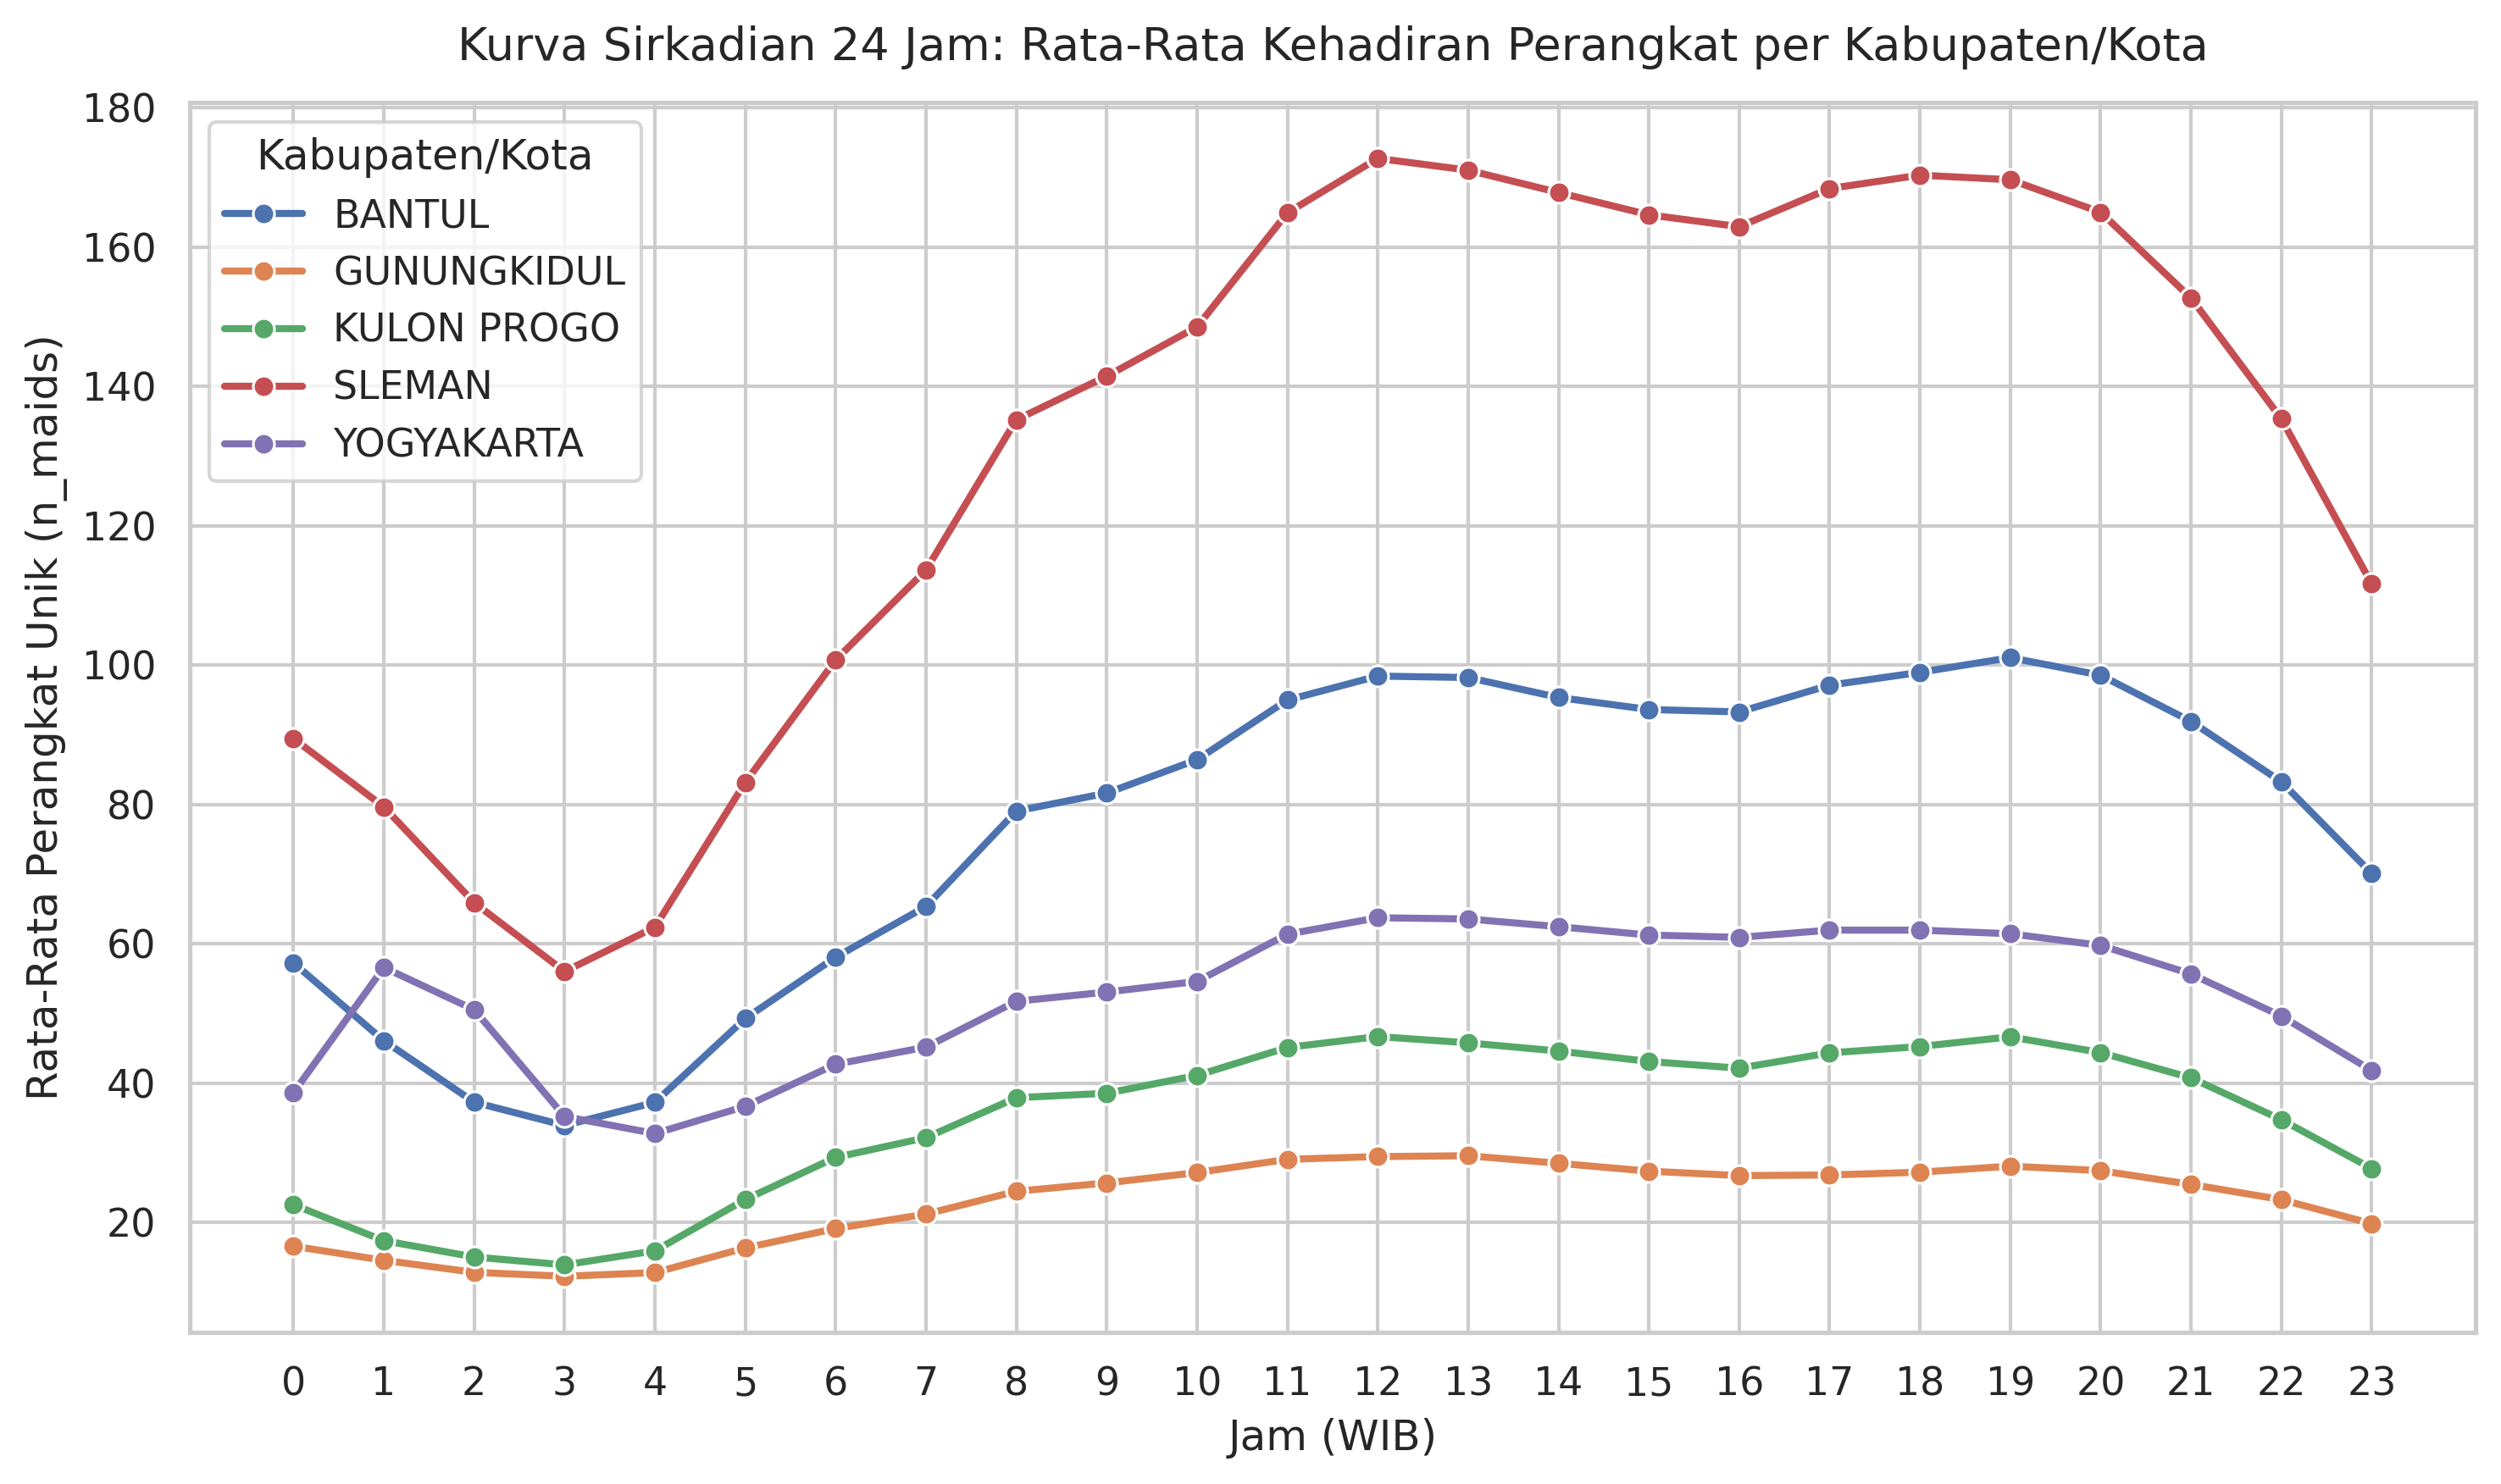

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=circadian_stats,
    x="hour",
    y="mean_maids",
    hue="kab_kota",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.set_title("Kurva Sirkadian 24 Jam: Rata-Rata Kehadiran Perangkat per Kabupaten/Kota", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Rata-Rata Perangkat Unik (n_maids)")
ax.set_xticks(range(0, 24))
ax.legend(title="Kabupaten/Kota", frameon=True)
plt.tight_layout()
plt.savefig("figures/01a_kurva_sirkadian_24jam.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_572/1322101968.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=day_night_ratio, x="kab_kota", y="rasio_siang_malam", palette="viridis", ax=ax)


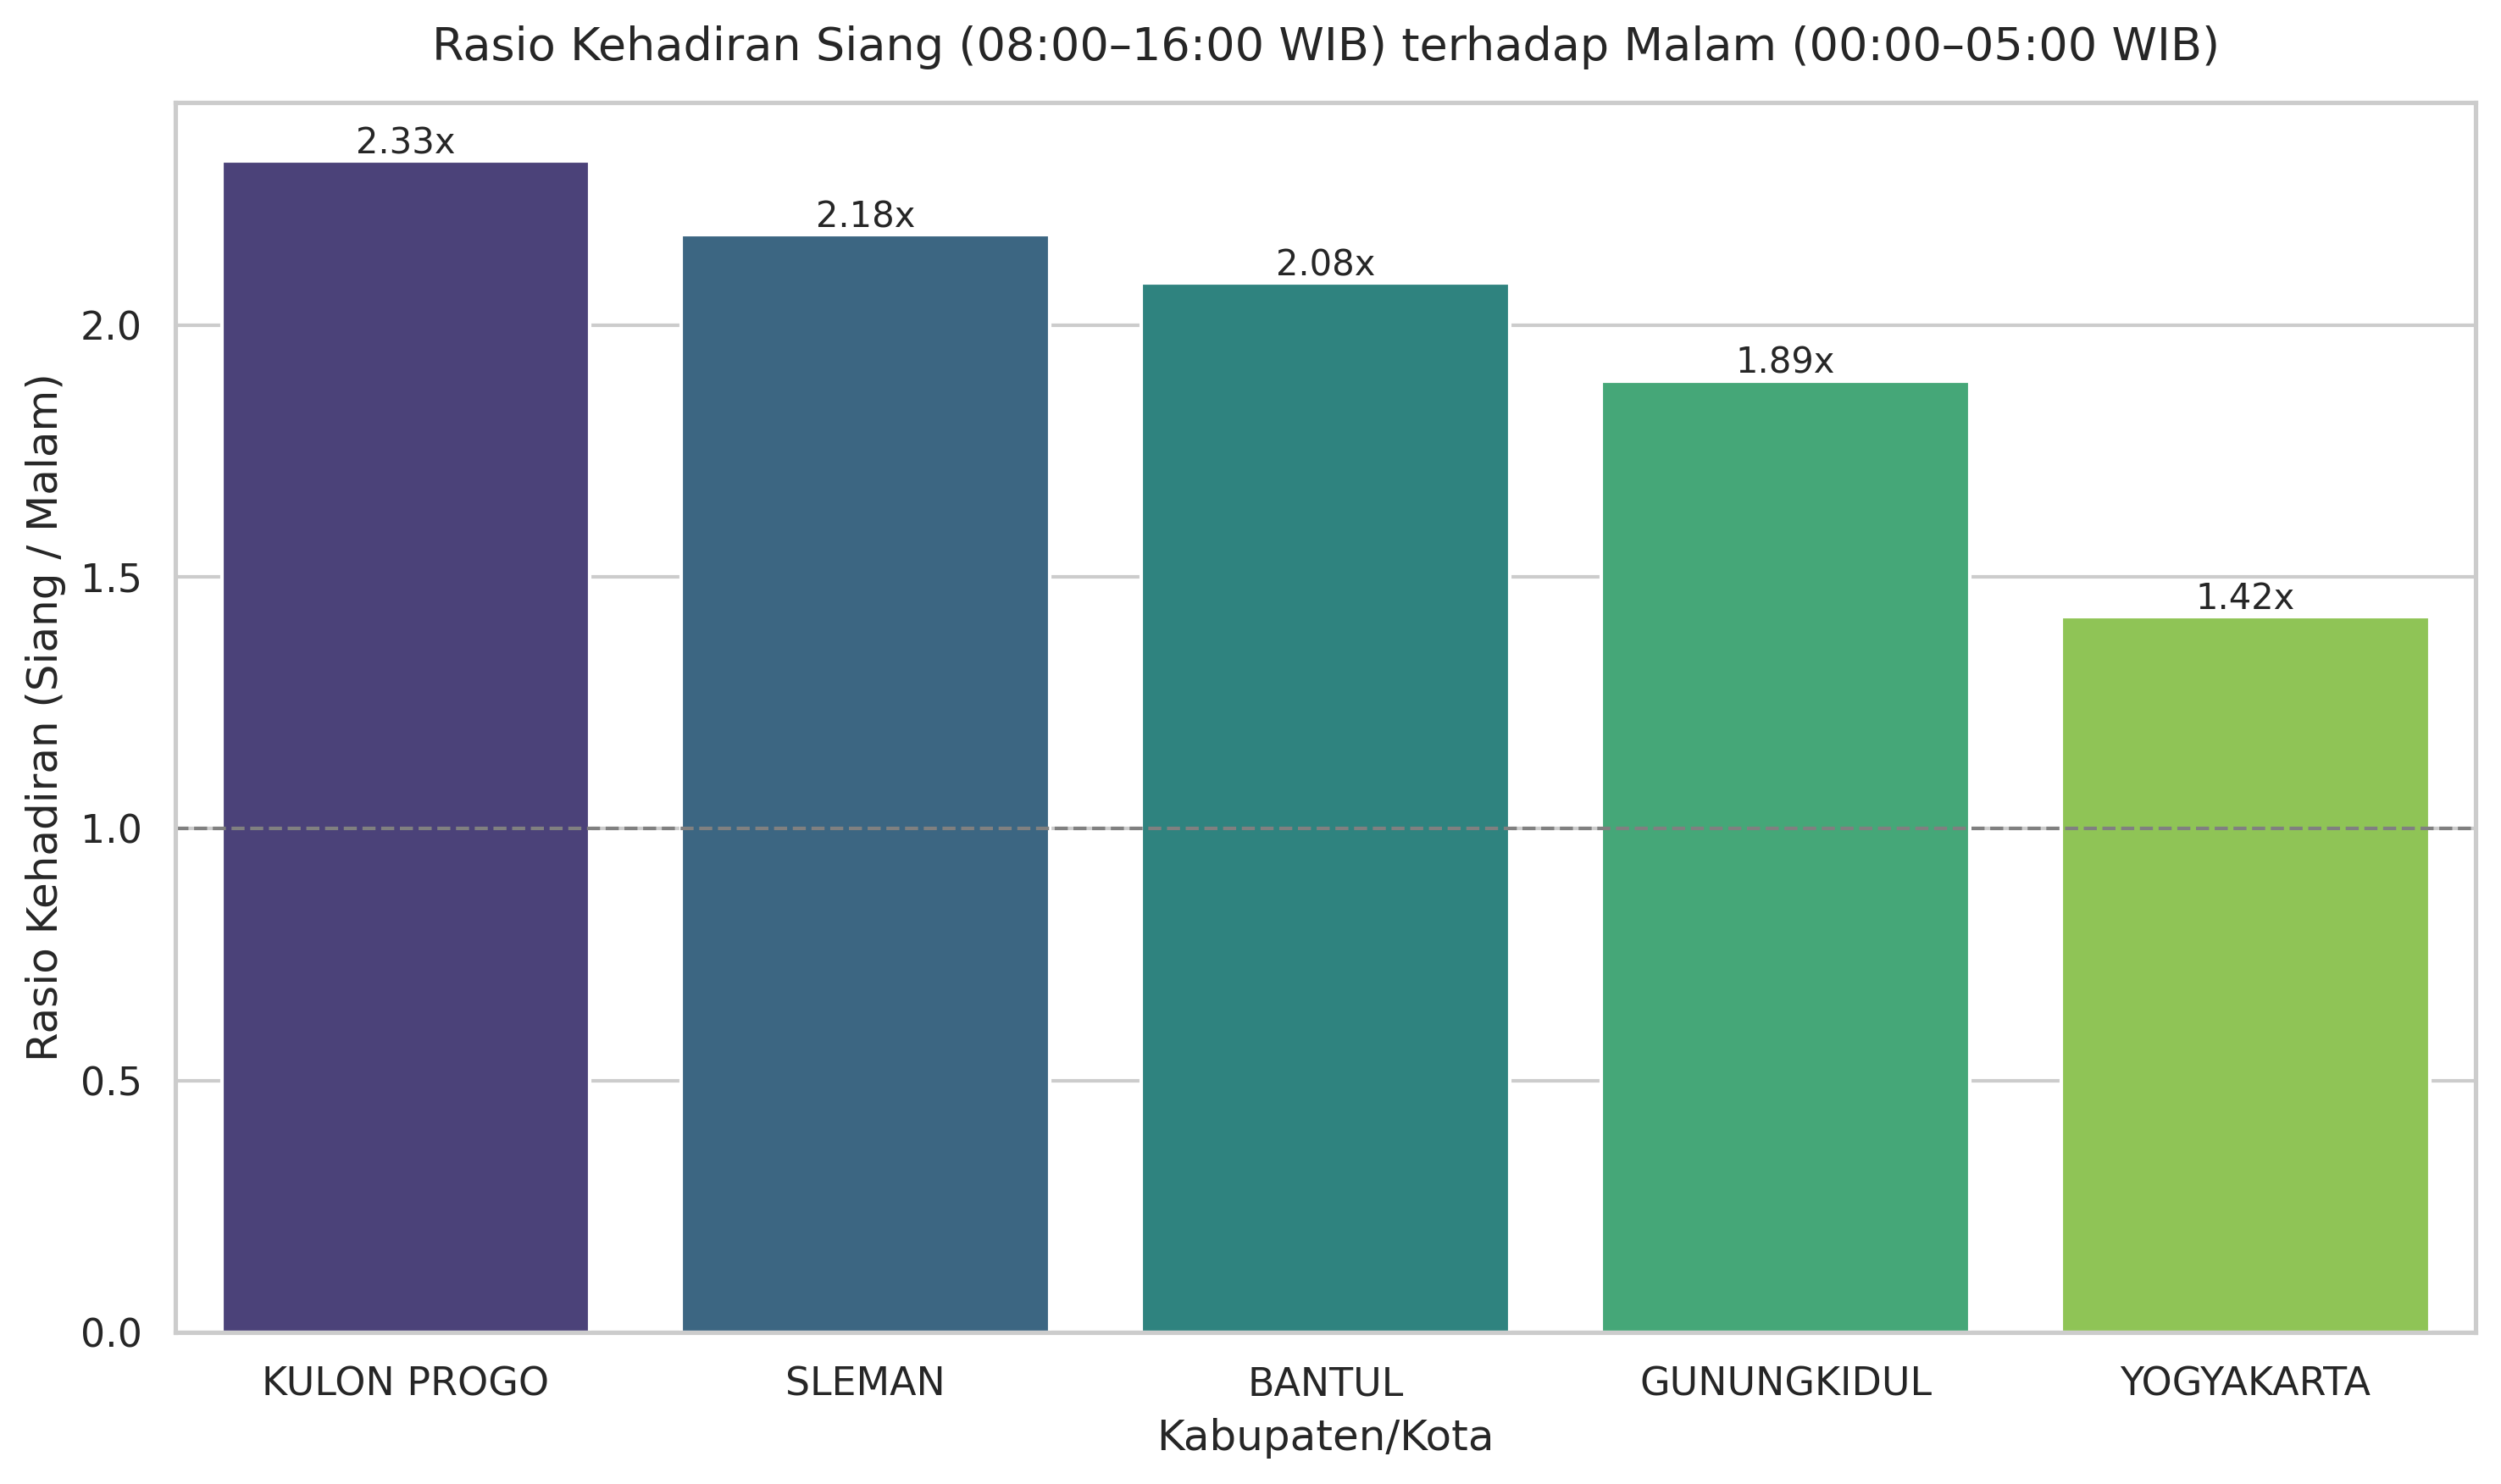

In [ ]:
day_mask = df_presence["hour"].between(8, 16)
night_mask = df_presence["hour"].between(0, 5)

day_mean = df_presence[day_mask].groupby("kab_kota")["n_maids"].mean()
night_mean = df_presence[night_mask].groupby("kab_kota")["n_maids"].mean()
day_night_ratio = (day_mean / night_mean).sort_values(ascending=False).reset_index(name="rasio_siang_malam")

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.barplot(data=day_night_ratio, x="kab_kota", y="rasio_siang_malam", palette="viridis", ax=ax)
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1)
for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():.2f}x",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_title("Rasio Kehadiran Siang (08:00–16:00 WIB) terhadap Malam (00:00–05:00 WIB)", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota")
ax.set_ylabel("Rasio Kehadiran (Siang / Malam)")
plt.tight_layout()
plt.savefig("figures/01b_rasio_siang_malam.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 2: Komparasi Hari Kerja (Weekday) vs Akhir Pekan (Weekend)

Mengelompokkan tanggal menjadi Hari Kerja (Senin–Jumat) dan Akhir Pekan (Sabtu–Minggu) untuk mengidentifikasi 15 kapanewon terpadat serta memetakan pola aktivitas mingguan dalam matriks 7 hari x 24 jam.

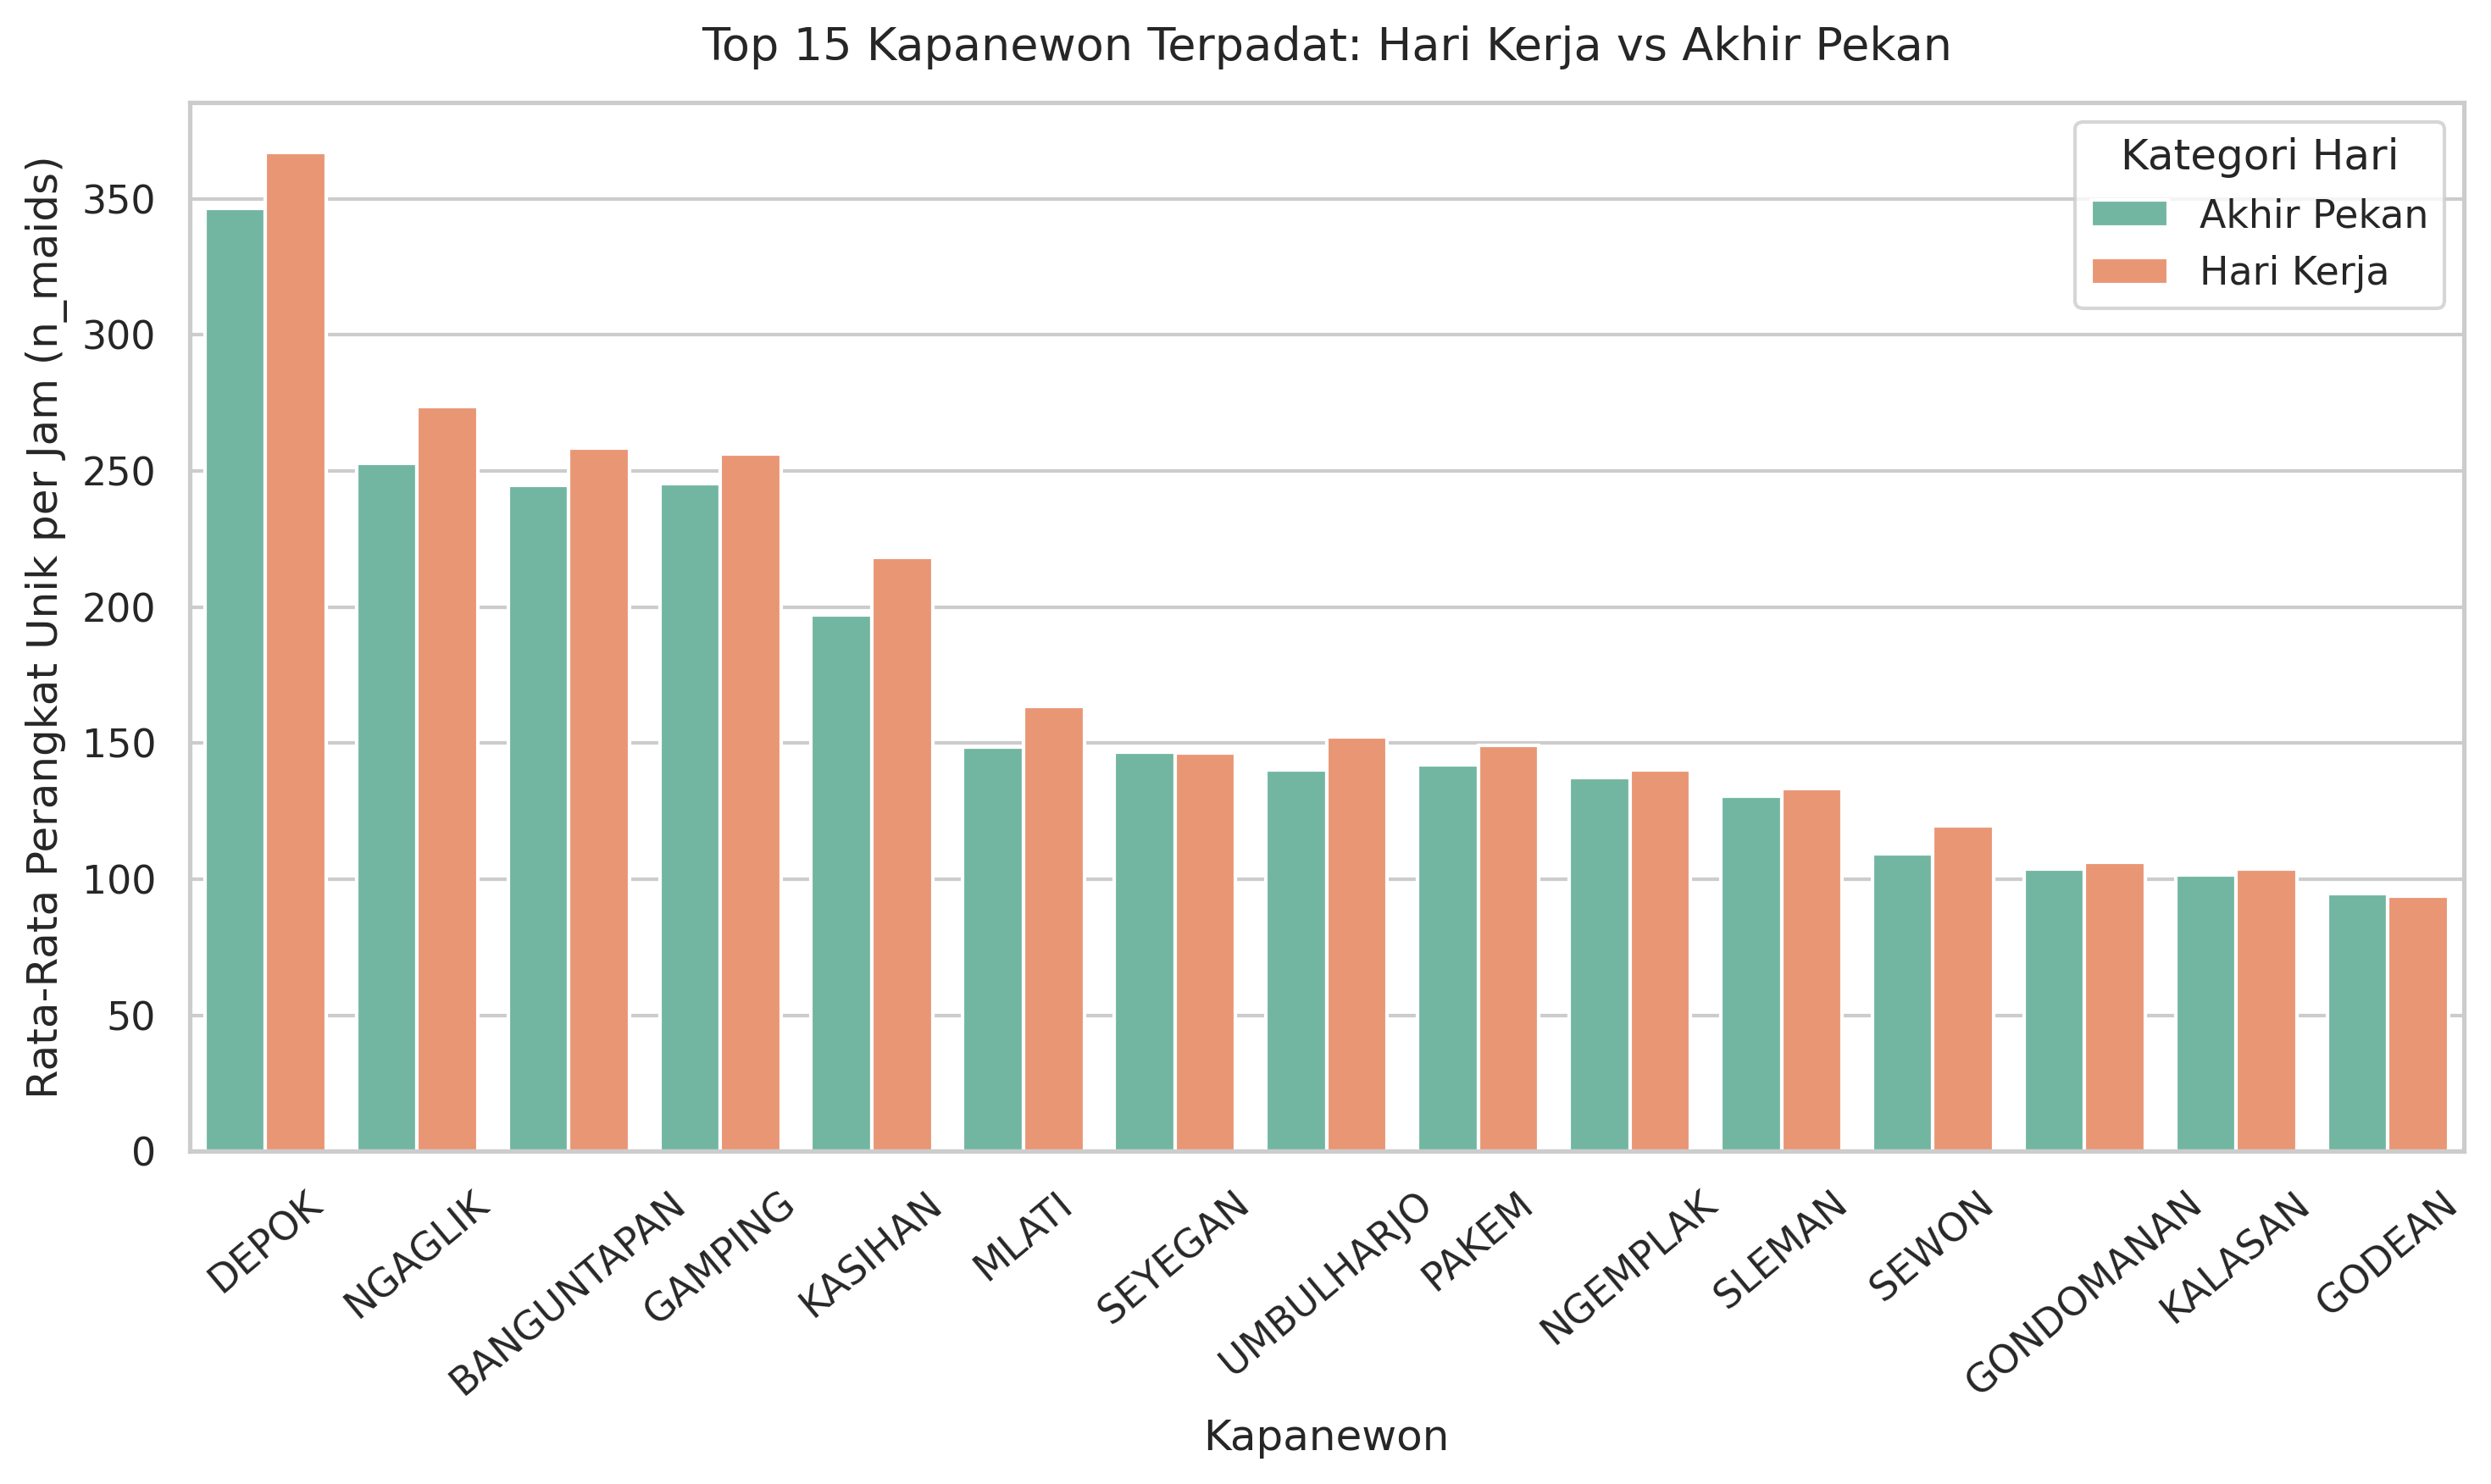

In [ ]:
df_presence["dayofweek"] = df_presence["date"].dt.dayofweek
day_map = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu",
}
day_order = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
df_presence["nama_hari"] = df_presence["dayofweek"].map(day_map)
df_presence["tipe_hari"] = np.where(df_presence["dayofweek"] < 5, "Hari Kerja", "Akhir Pekan")

kapanewon_daytype = (
    df_presence.groupby(["kapanewon", "tipe_hari"])["n_maids"]
    .mean()
    .reset_index()
)
top15_kapanewon = (
    df_presence.groupby("kapanewon")["n_maids"]
    .mean()
    .nlargest(15)
    .index
)
top15_df = kapanewon_daytype[kapanewon_daytype["kapanewon"].isin(top15_kapanewon)].copy()
order_top15 = (
    top15_df.groupby("kapanewon")["n_maids"].mean().sort_values(ascending=False).index
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.barplot(
    data=top15_df,
    x="kapanewon",
    y="n_maids",
    hue="tipe_hari",
    order=order_top15,
    palette="Set2",
    ax=ax,
)
ax.set_title("Top 15 Kapanewon Terpadat: Hari Kerja vs Akhir Pekan", fontsize=13, pad=12)
ax.set_xlabel("Kapanewon")
ax.set_ylabel("Rata-Rata Perangkat Unik per Jam (n_maids)")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Kategori Hari", frameon=True)
plt.tight_layout()
plt.savefig("figures/02a_top15_kapanewon_weekday_weekend.png", dpi=300, bbox_inches="tight")
plt.show()

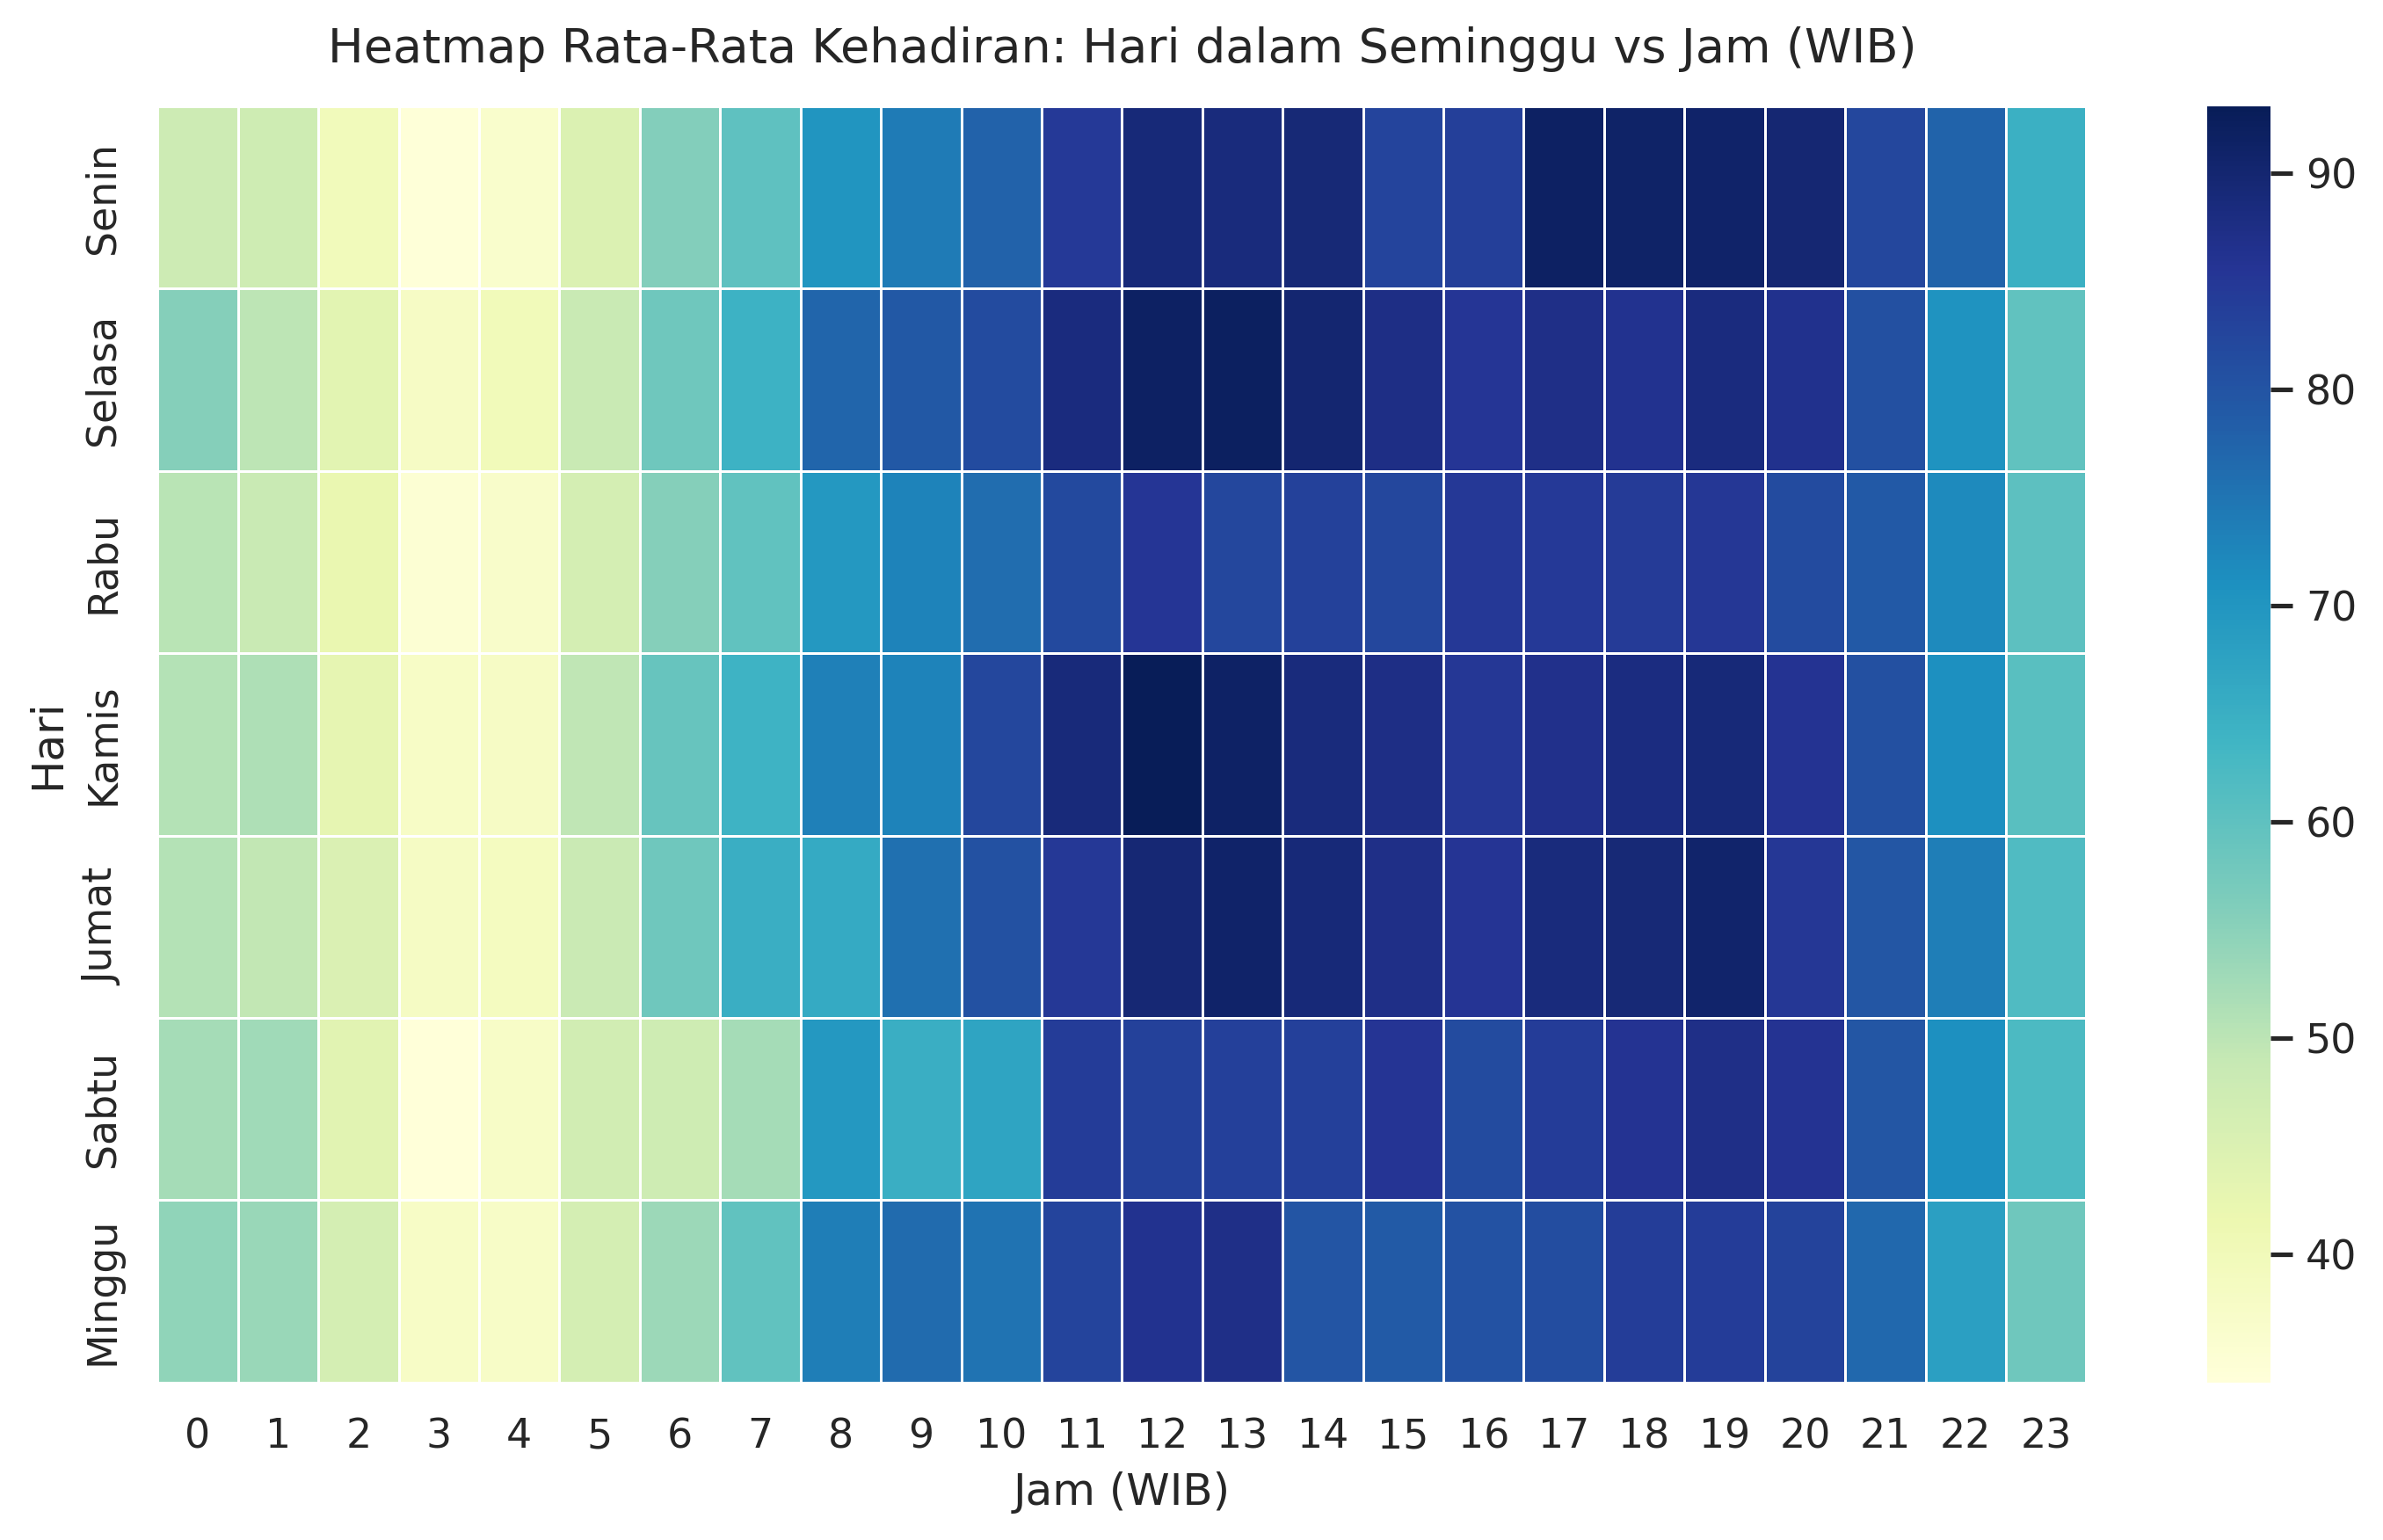

In [ ]:
heatmap_day_hour = (
    df_presence.groupby(["nama_hari", "hour"])["n_maids"]
    .mean()
    .unstack(level="hour")
    .reindex(day_order)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.heatmap(heatmap_day_hour, cmap="YlGnBu", linewidths=0.3, ax=ax)
ax.set_title("Heatmap Rata-Rata Kehadiran: Hari dalam Seminggu vs Jam (WIB)", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Hari")
plt.tight_layout()
plt.savefig("figures/02b_heatmap_hari_vs_jam.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 3: Tren Longitudinal 151 Hari, Libur Tahun Baru, & Pergeseran Ramadhan

Mengagregasi total kehadiran harian selama 151 hari (1 Desember 2021 – 30 April 2022) untuk melihat dinamika musiman, serta membandingkan profil jam aktif antara periode normal (Desember 2021–Maret 2022) dan bulan Ramadhan 1443 H (April 2022).

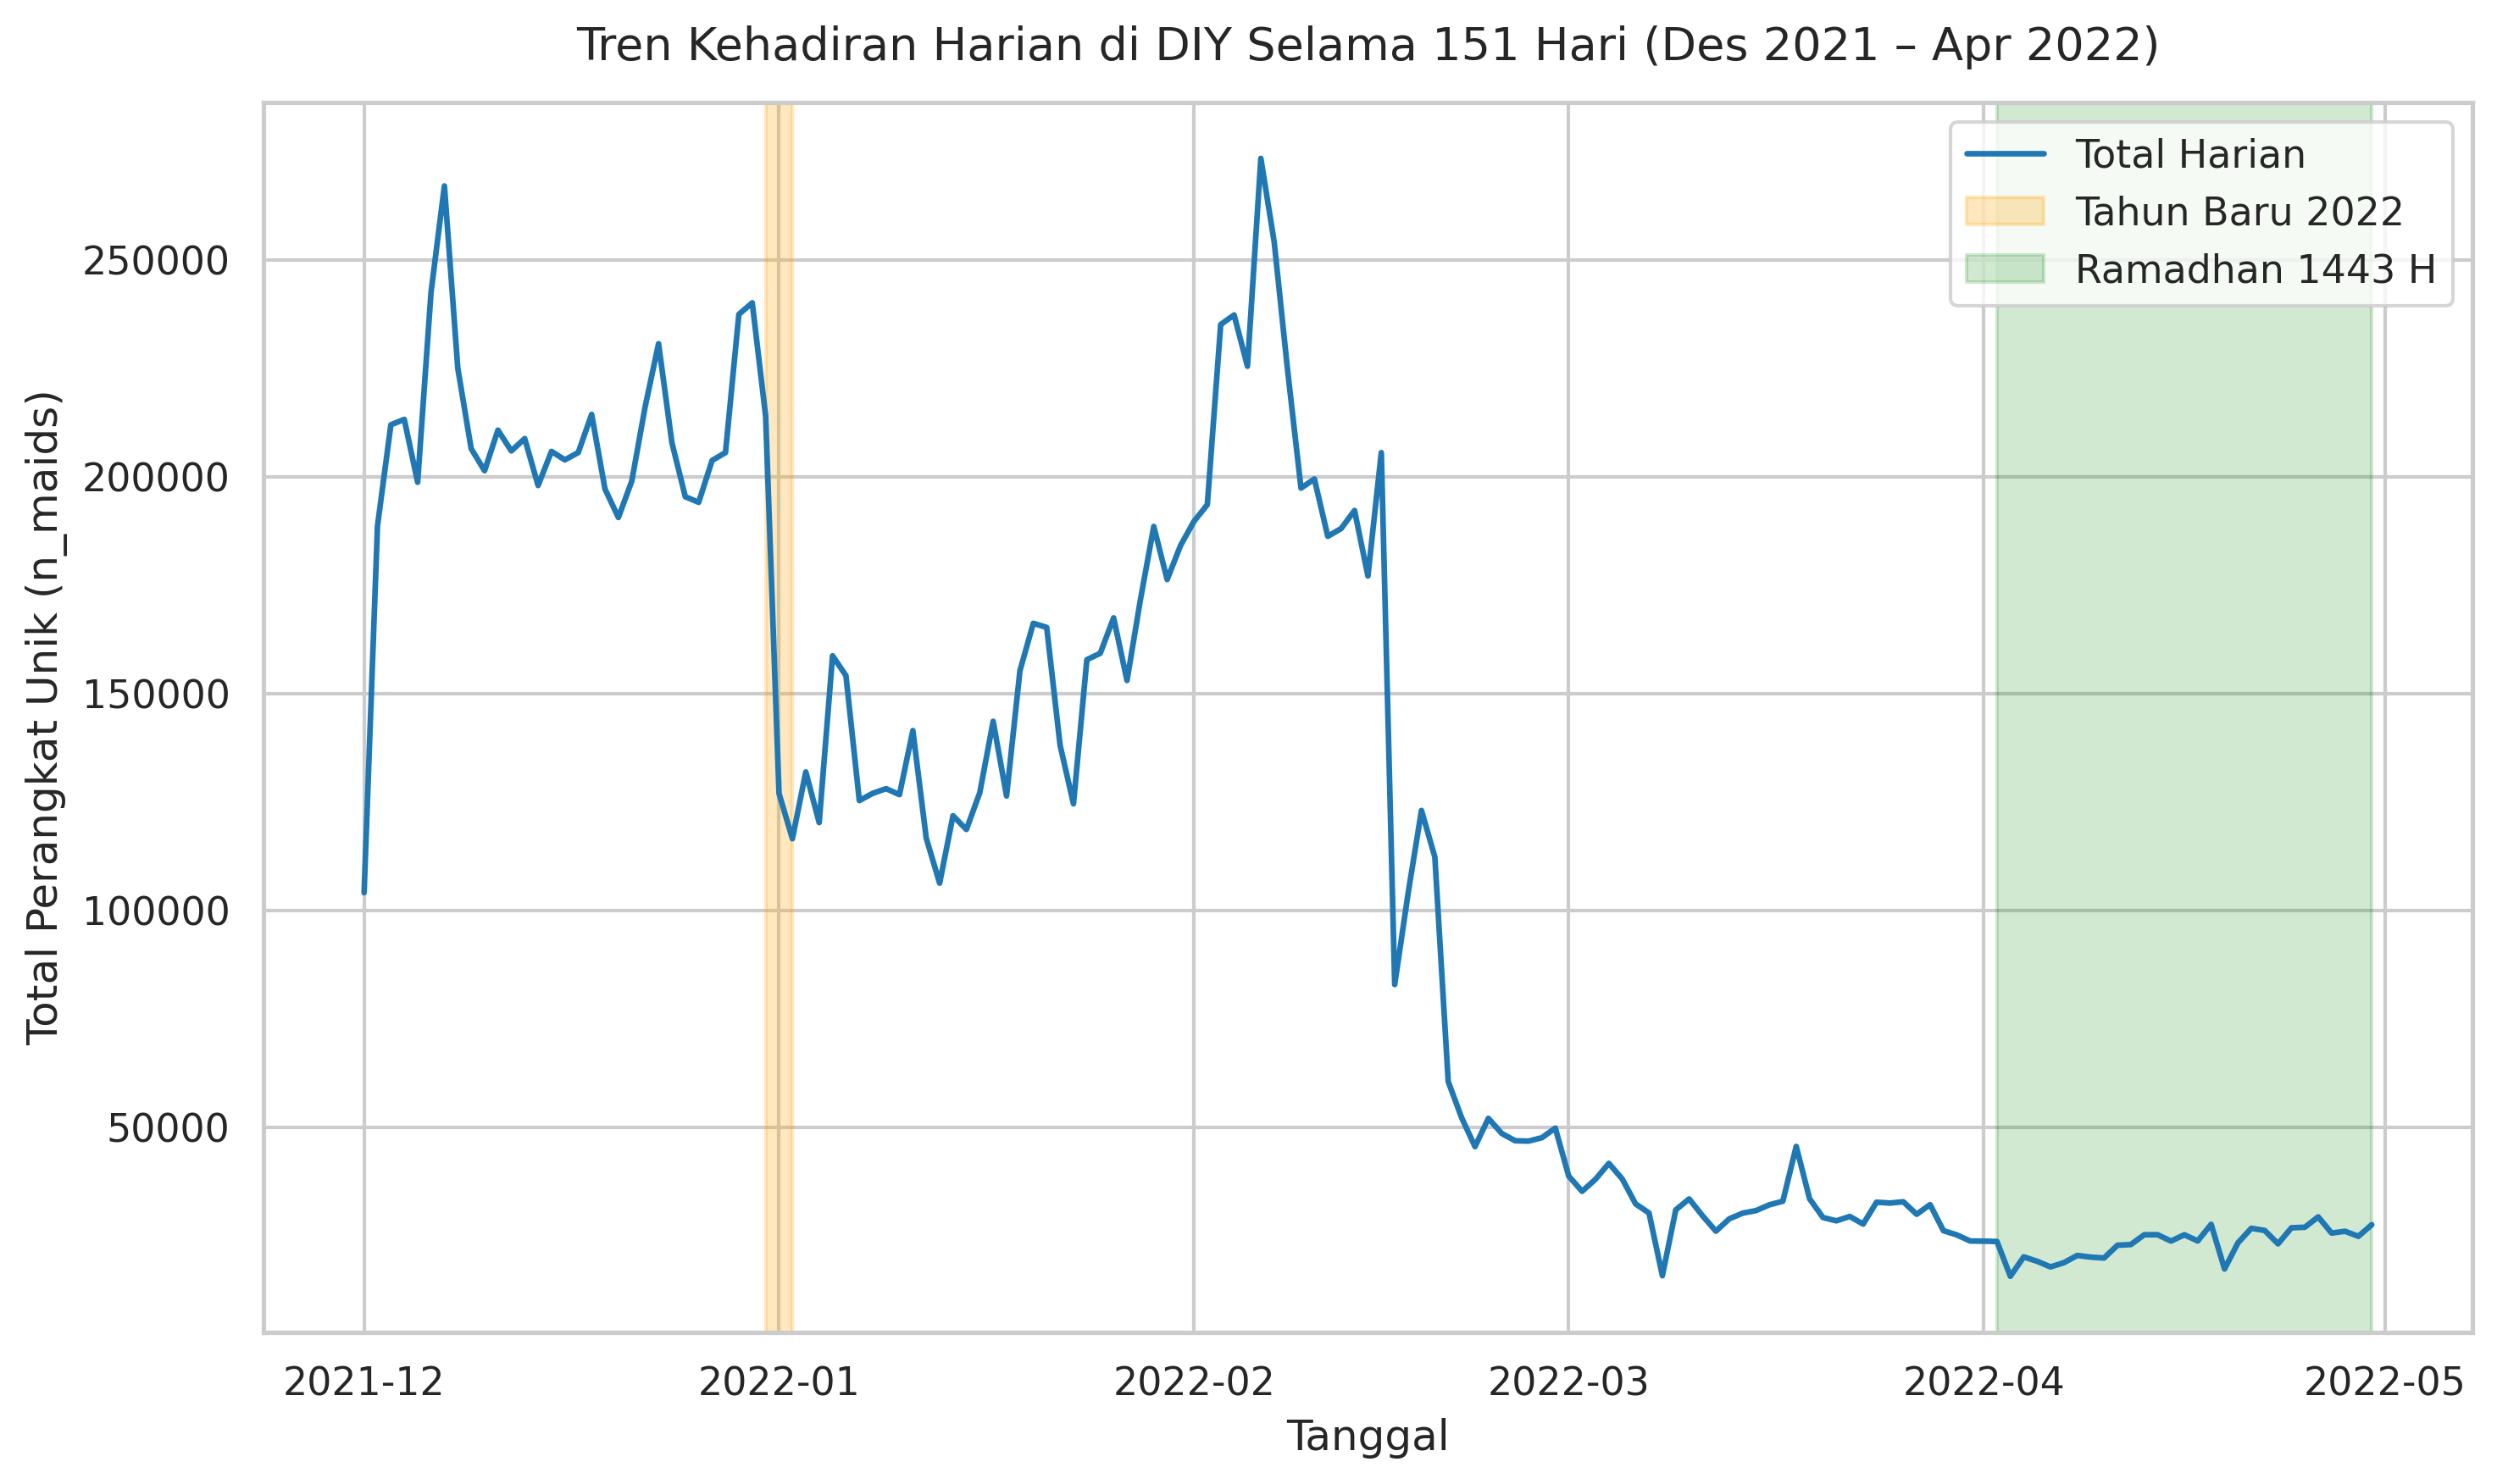

In [ ]:
daily_trend = df_presence.groupby("date")["n_maids"].sum().reset_index()

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.plot(daily_trend["date"], daily_trend["n_maids"], color="#1f77b4", linewidth=1.6, label="Total Harian")
ax.axvspan(pd.Timestamp("2021-12-31"), pd.Timestamp("2022-01-02"), color="orange", alpha=0.25, label="Tahun Baru 2022")
ax.axvspan(pd.Timestamp("2022-04-02"), pd.Timestamp("2022-04-30"), color="green", alpha=0.18, label="Ramadhan 1443 H")
ax.set_title("Tren Kehadiran Harian di DIY Selama 151 Hari (Des 2021 – Apr 2022)", fontsize=13, pad=12)
ax.set_xlabel("Tanggal")
ax.set_ylabel("Total Perangkat Unik (n_maids)")
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/03a_tren_harian_151hari.png", dpi=300, bbox_inches="tight")
plt.show()

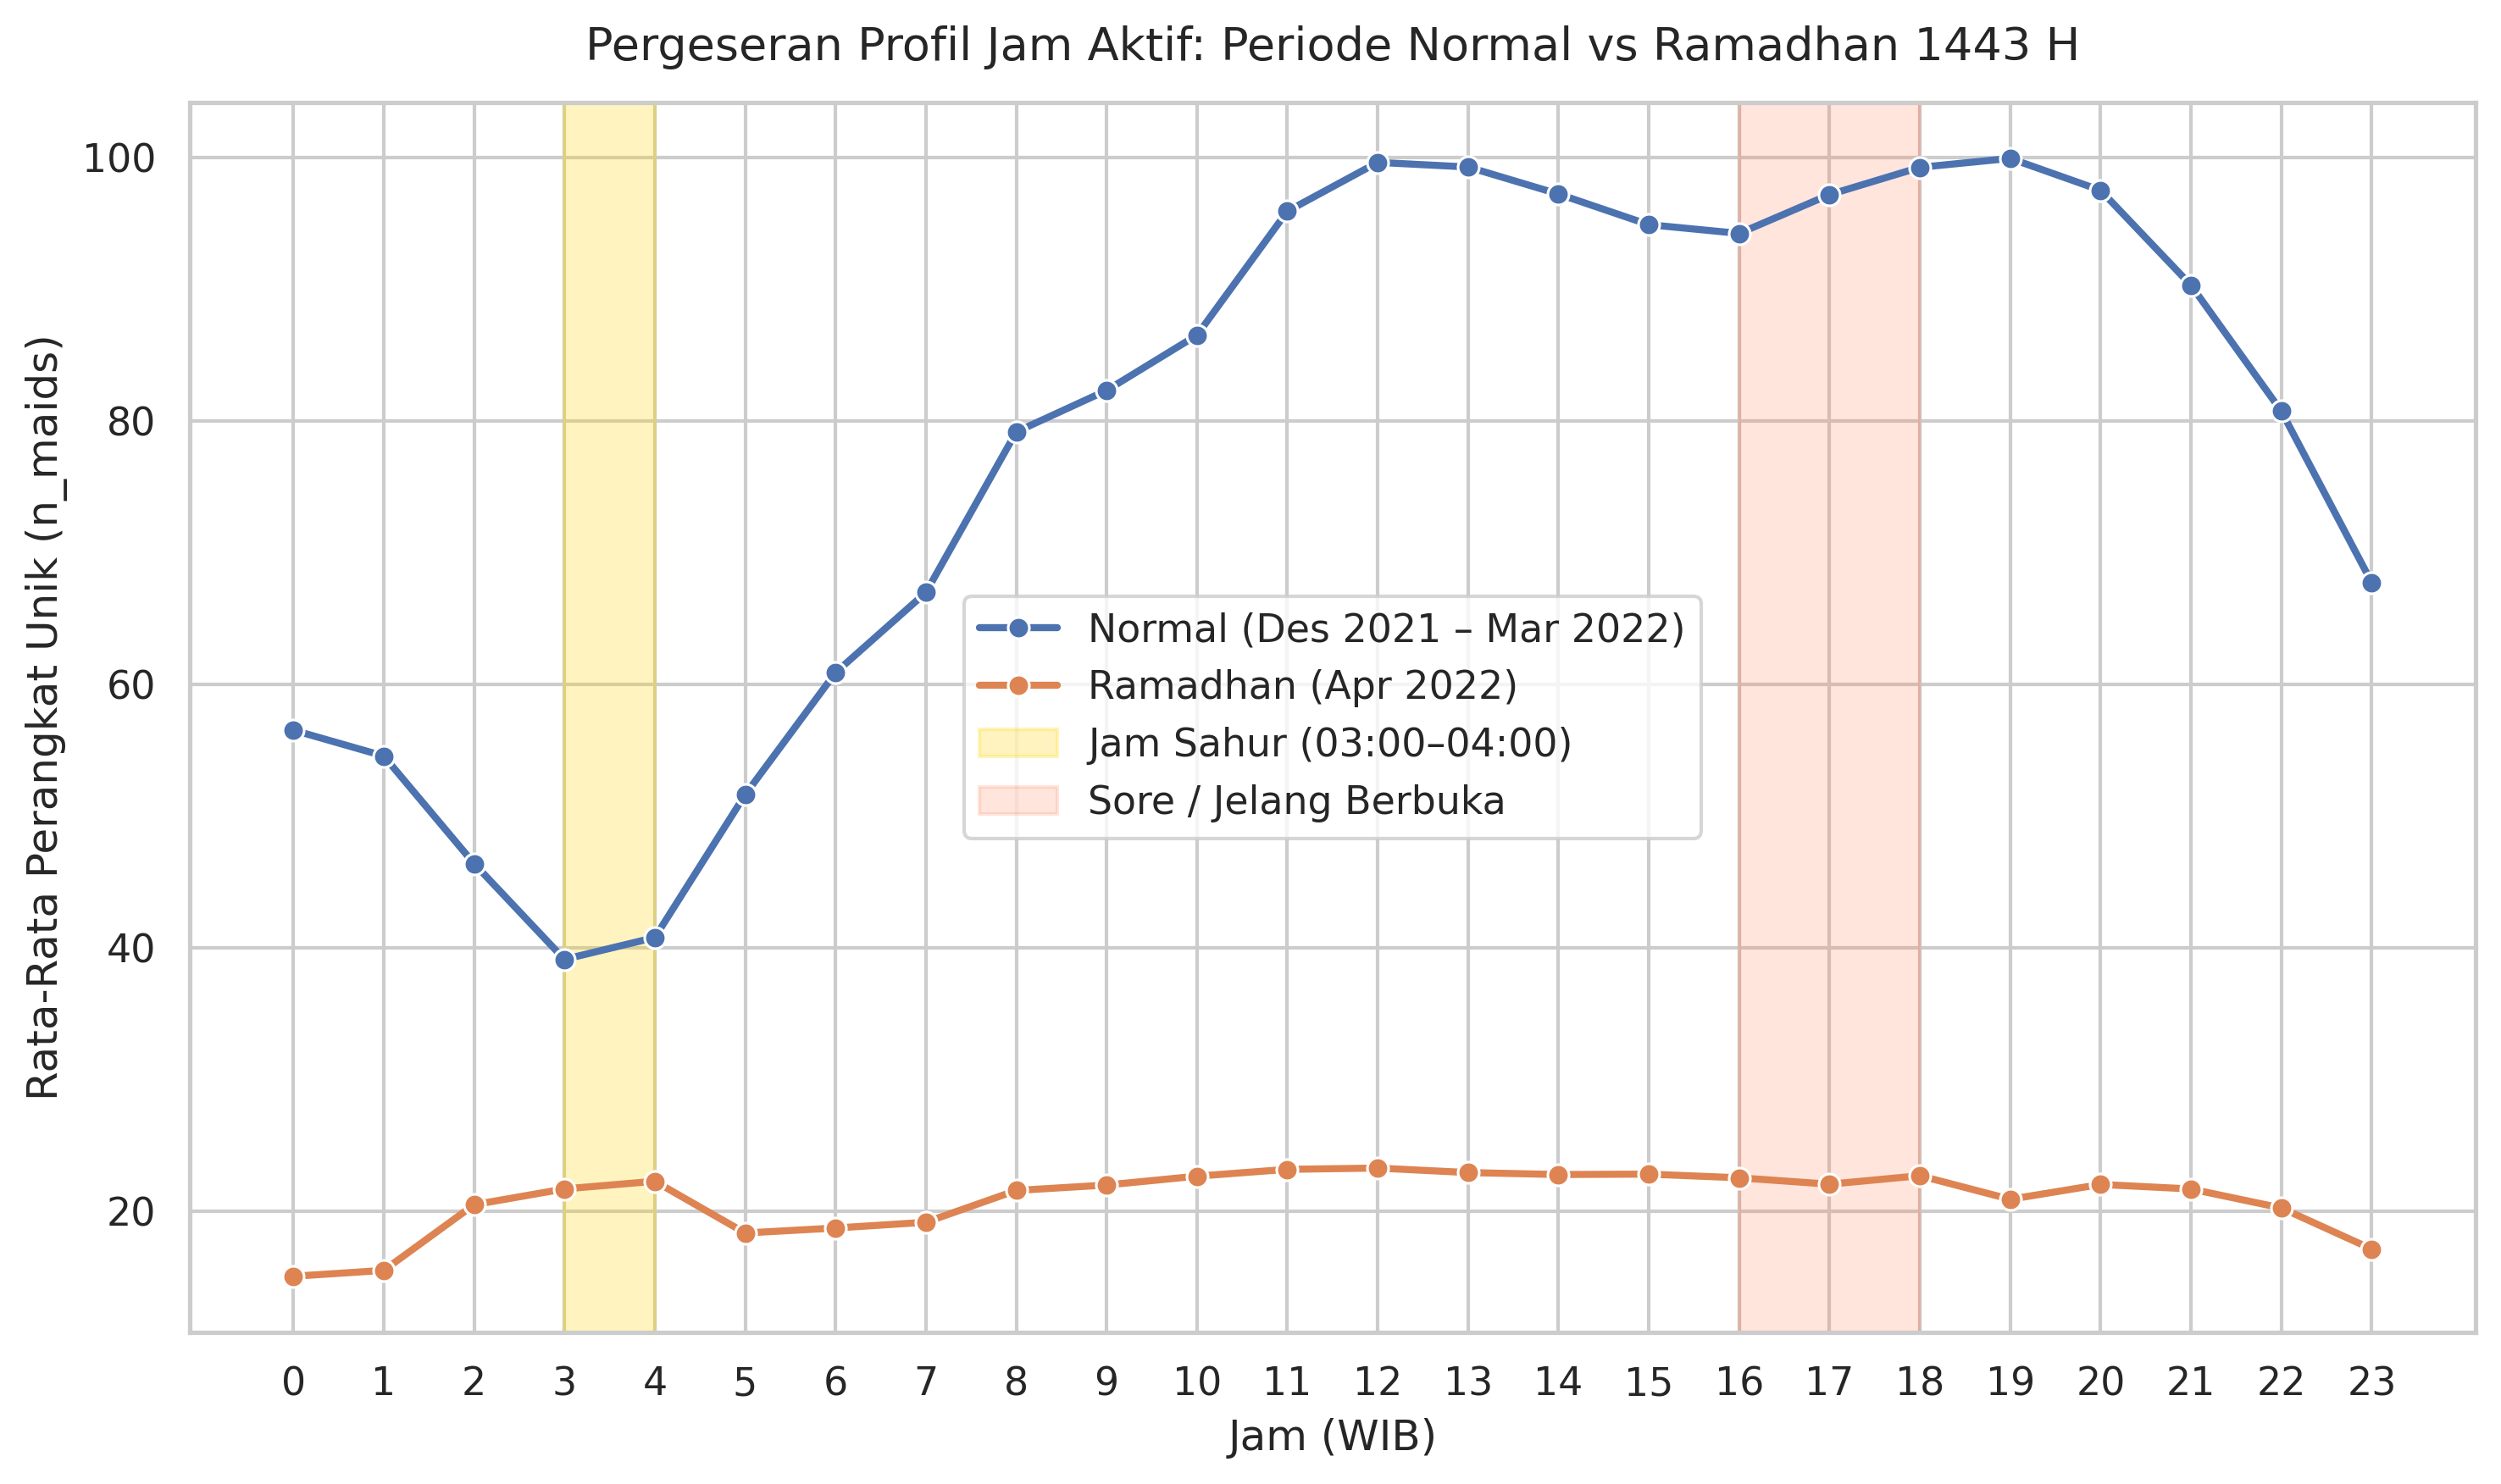

In [ ]:
df_presence["periode"] = np.where(
    df_presence["date"] >= pd.Timestamp("2022-04-01"),
    "Ramadhan (Apr 2022)",
    "Normal (Des 2021 – Mar 2022)",
)
ramadhan_hourly = (
    df_presence.groupby(["periode", "hour"])["n_maids"]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=ramadhan_hourly,
    x="hour",
    y="n_maids",
    hue="periode",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.axvspan(3, 4, color="gold", alpha=0.25, label="Jam Sahur (03:00–04:00)")
ax.axvspan(16, 18, color="coral", alpha=0.2, label="Sore / Jelang Berbuka")
ax.set_title("Pergeseran Profil Jam Aktif: Periode Normal vs Ramadhan 1443 H", fontsize=13, pad=12)
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Rata-Rata Perangkat Unik (n_maids)")
ax.set_xticks(range(0, 24))
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig("figures/03b_pergeseran_jam_ramadhan.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 4: Analisis Intensitas Aktivitas Sinyal (Rasio Pings per Perangkat)

Menghitung metrik `pings_per_maid = n_pings / n_maids` untuk mengukur intensitas pengiriman sinyal GPS per perangkat di setiap Kabupaten/Kota, kapanewon, dan jam.

In [ ]:
df_presence["pings_per_maid"] = np.where(
    df_presence["n_maids"] > 0,
    df_presence["n_pings"] / df_presence["n_maids"],
    np.nan,
)

ping_summary = (
    df_presence.groupby("kab_kota")[["n_maids", "n_pings", "pings_per_maid"]]
    .mean()
    .round(2)
)
ping_summary

,n_maids,n_pings,pings_per_maid
kab_kota,,,
BANTUL,78.83,191.01,2.50
GUNUNGKIDUL,24.53,63.21,2.63
KULON PROGO,36.46,98.56,2.62
SLEMAN,132.99,363.44,2.64
YOGYAKARTA,53.34,151.62,2.65


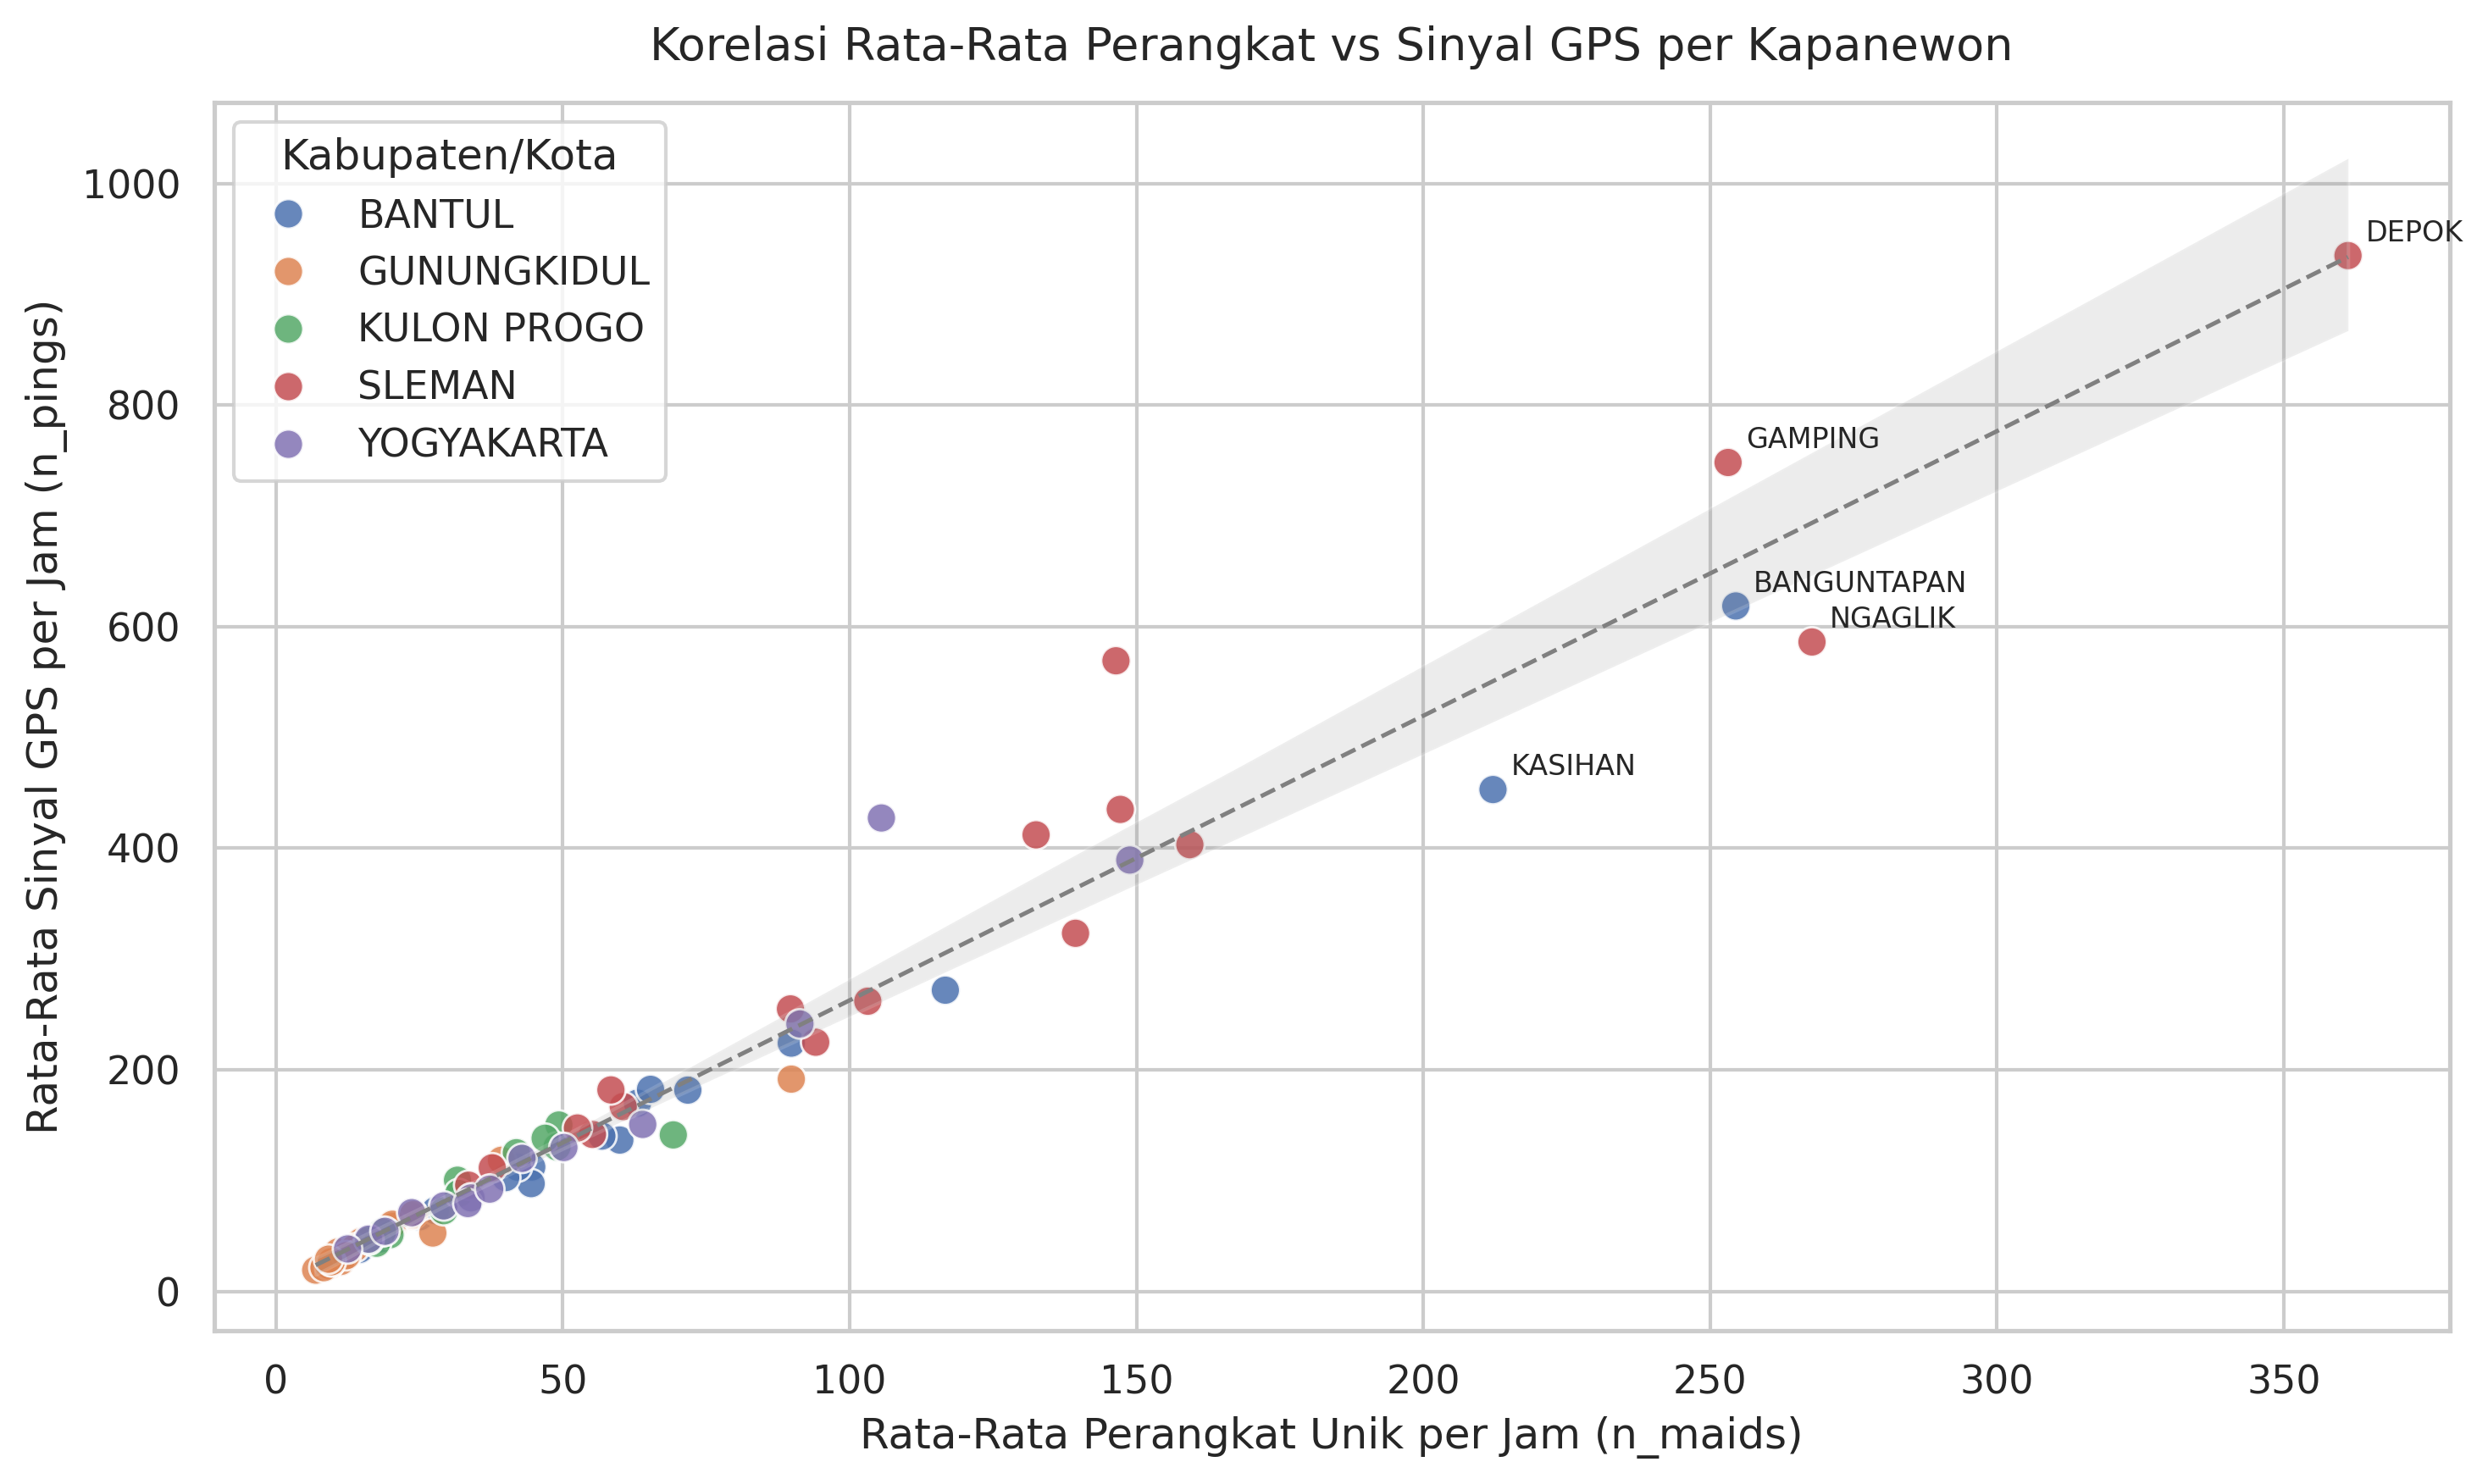

In [ ]:
kapanewon_agg = (
    df_presence.groupby(["kab_kota", "kapanewon"])[["n_maids", "n_pings"]]
    .mean()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.scatterplot(
    data=kapanewon_agg,
    x="n_maids",
    y="n_pings",
    hue="kab_kota",
    s=70,
    alpha=0.85,
    ax=ax,
)
sns.regplot(
    data=kapanewon_agg,
    x="n_maids",
    y="n_pings",
    scatter=False,
    color="gray",
    line_kws={"linestyle": "--", "linewidth": 1.2},
    ax=ax,
)

for _, row in kapanewon_agg.nlargest(5, "n_maids").iterrows():
    ax.annotate(
        row["kapanewon"],
        (row["n_maids"], row["n_pings"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title("Korelasi Rata-Rata Perangkat vs Sinyal GPS per Kapanewon", fontsize=13, pad=12)
ax.set_xlabel("Rata-Rata Perangkat Unik per Jam (n_maids)")
ax.set_ylabel("Rata-Rata Sinyal GPS per Jam (n_pings)")
ax.legend(title="Kabupaten/Kota", frameon=True)
plt.tight_layout()
plt.savefig("figures/04a_scatter_maids_vs_pings.png", dpi=300, bbox_inches="tight")
plt.show()

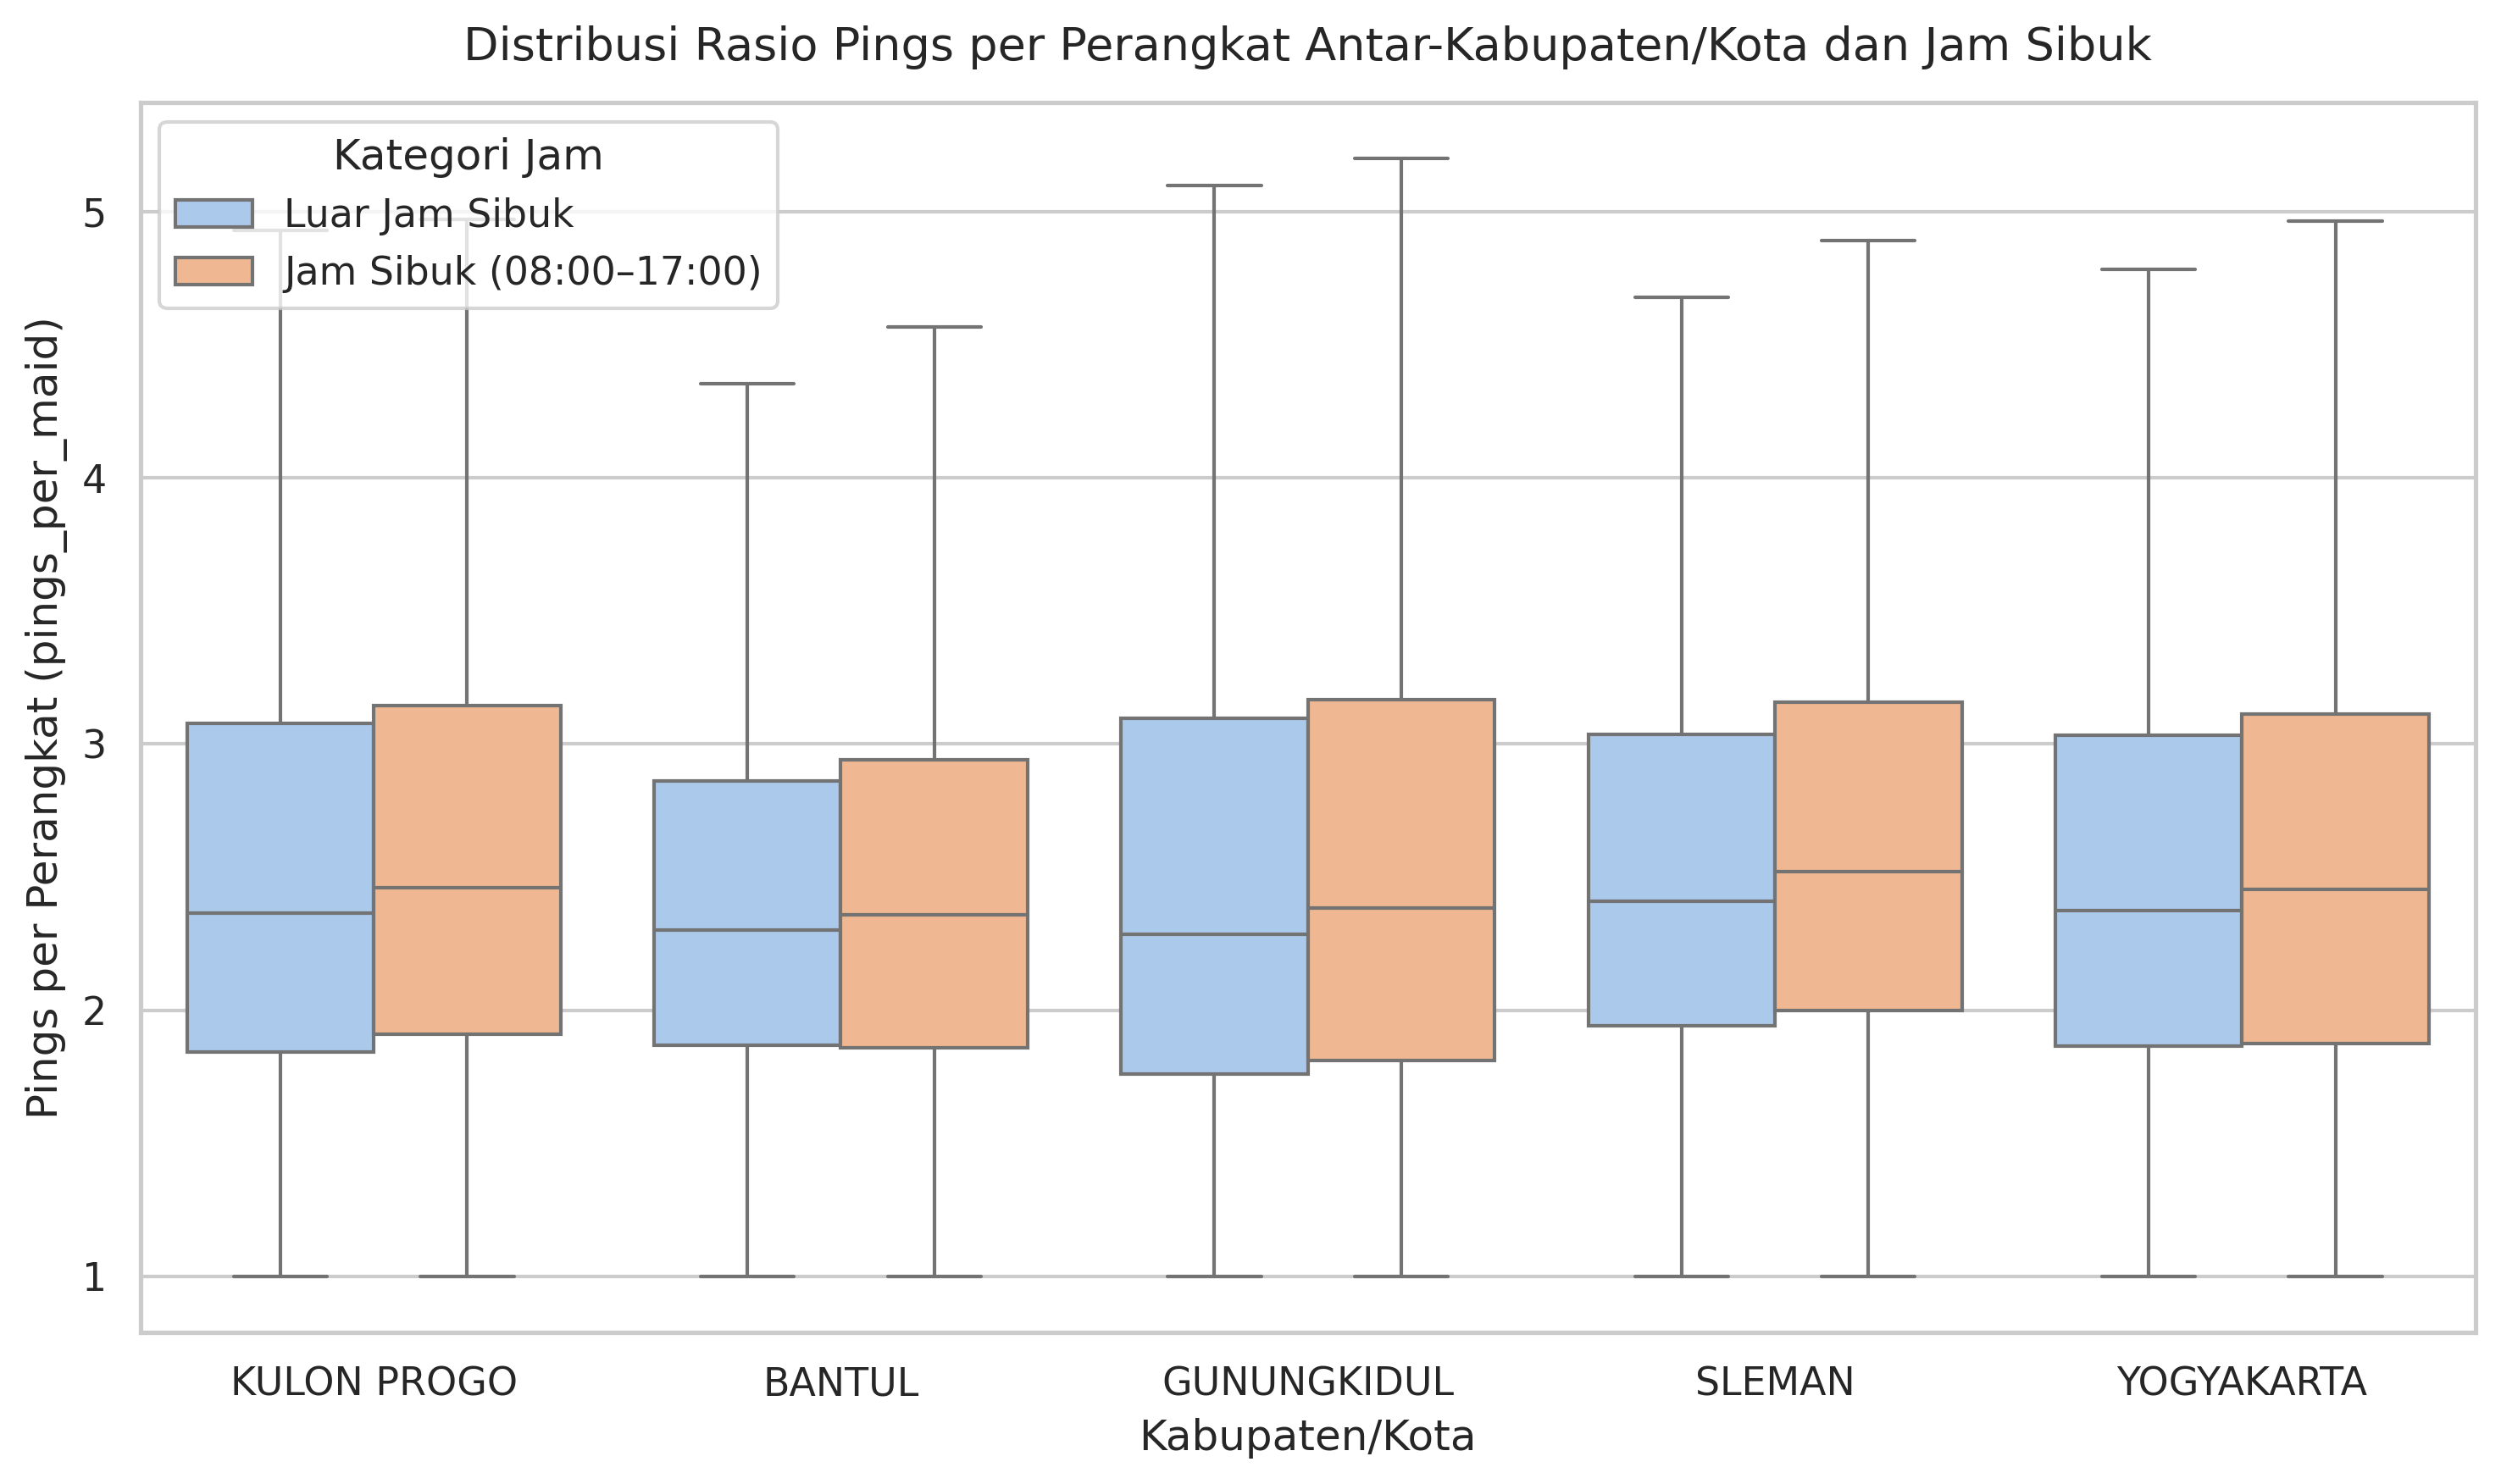

In [ ]:
jam_sibuk = df_presence["hour"].between(8, 17)
df_presence["kategori_jam"] = np.where(jam_sibuk, "Jam Sibuk (08:00–17:00)", "Luar Jam Sibuk")

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.boxplot(
    data=df_presence,
    x="kab_kota",
    y="pings_per_maid",
    hue="kategori_jam",
    showfliers=False,
    palette="pastel",
    ax=ax,
)
ax.set_title("Distribusi Rasio Pings per Perangkat Antar-Kabupaten/Kota dan Jam Sibuk", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota")
ax.set_ylabel("Pings per Perangkat (pings_per_maid)")
ax.legend(title="Kategori Jam", frameon=True)
plt.tight_layout()
plt.savefig("figures/04b_boxplot_pings_per_maid.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 5: Matriks Origin-Destination (OD) Makro Antar-Kabupaten/Kota

Mengagregasi aliran pergerakan siang hari (`n_maids`) berdasarkan kabupaten asal (`origin_kab_kota`) dan kabupaten tujuan (`dest_kab_kota`) untuk melihat matriks OD 5x5 serta proporsi pergerakan *intra-regency* vs *inter-regency*.

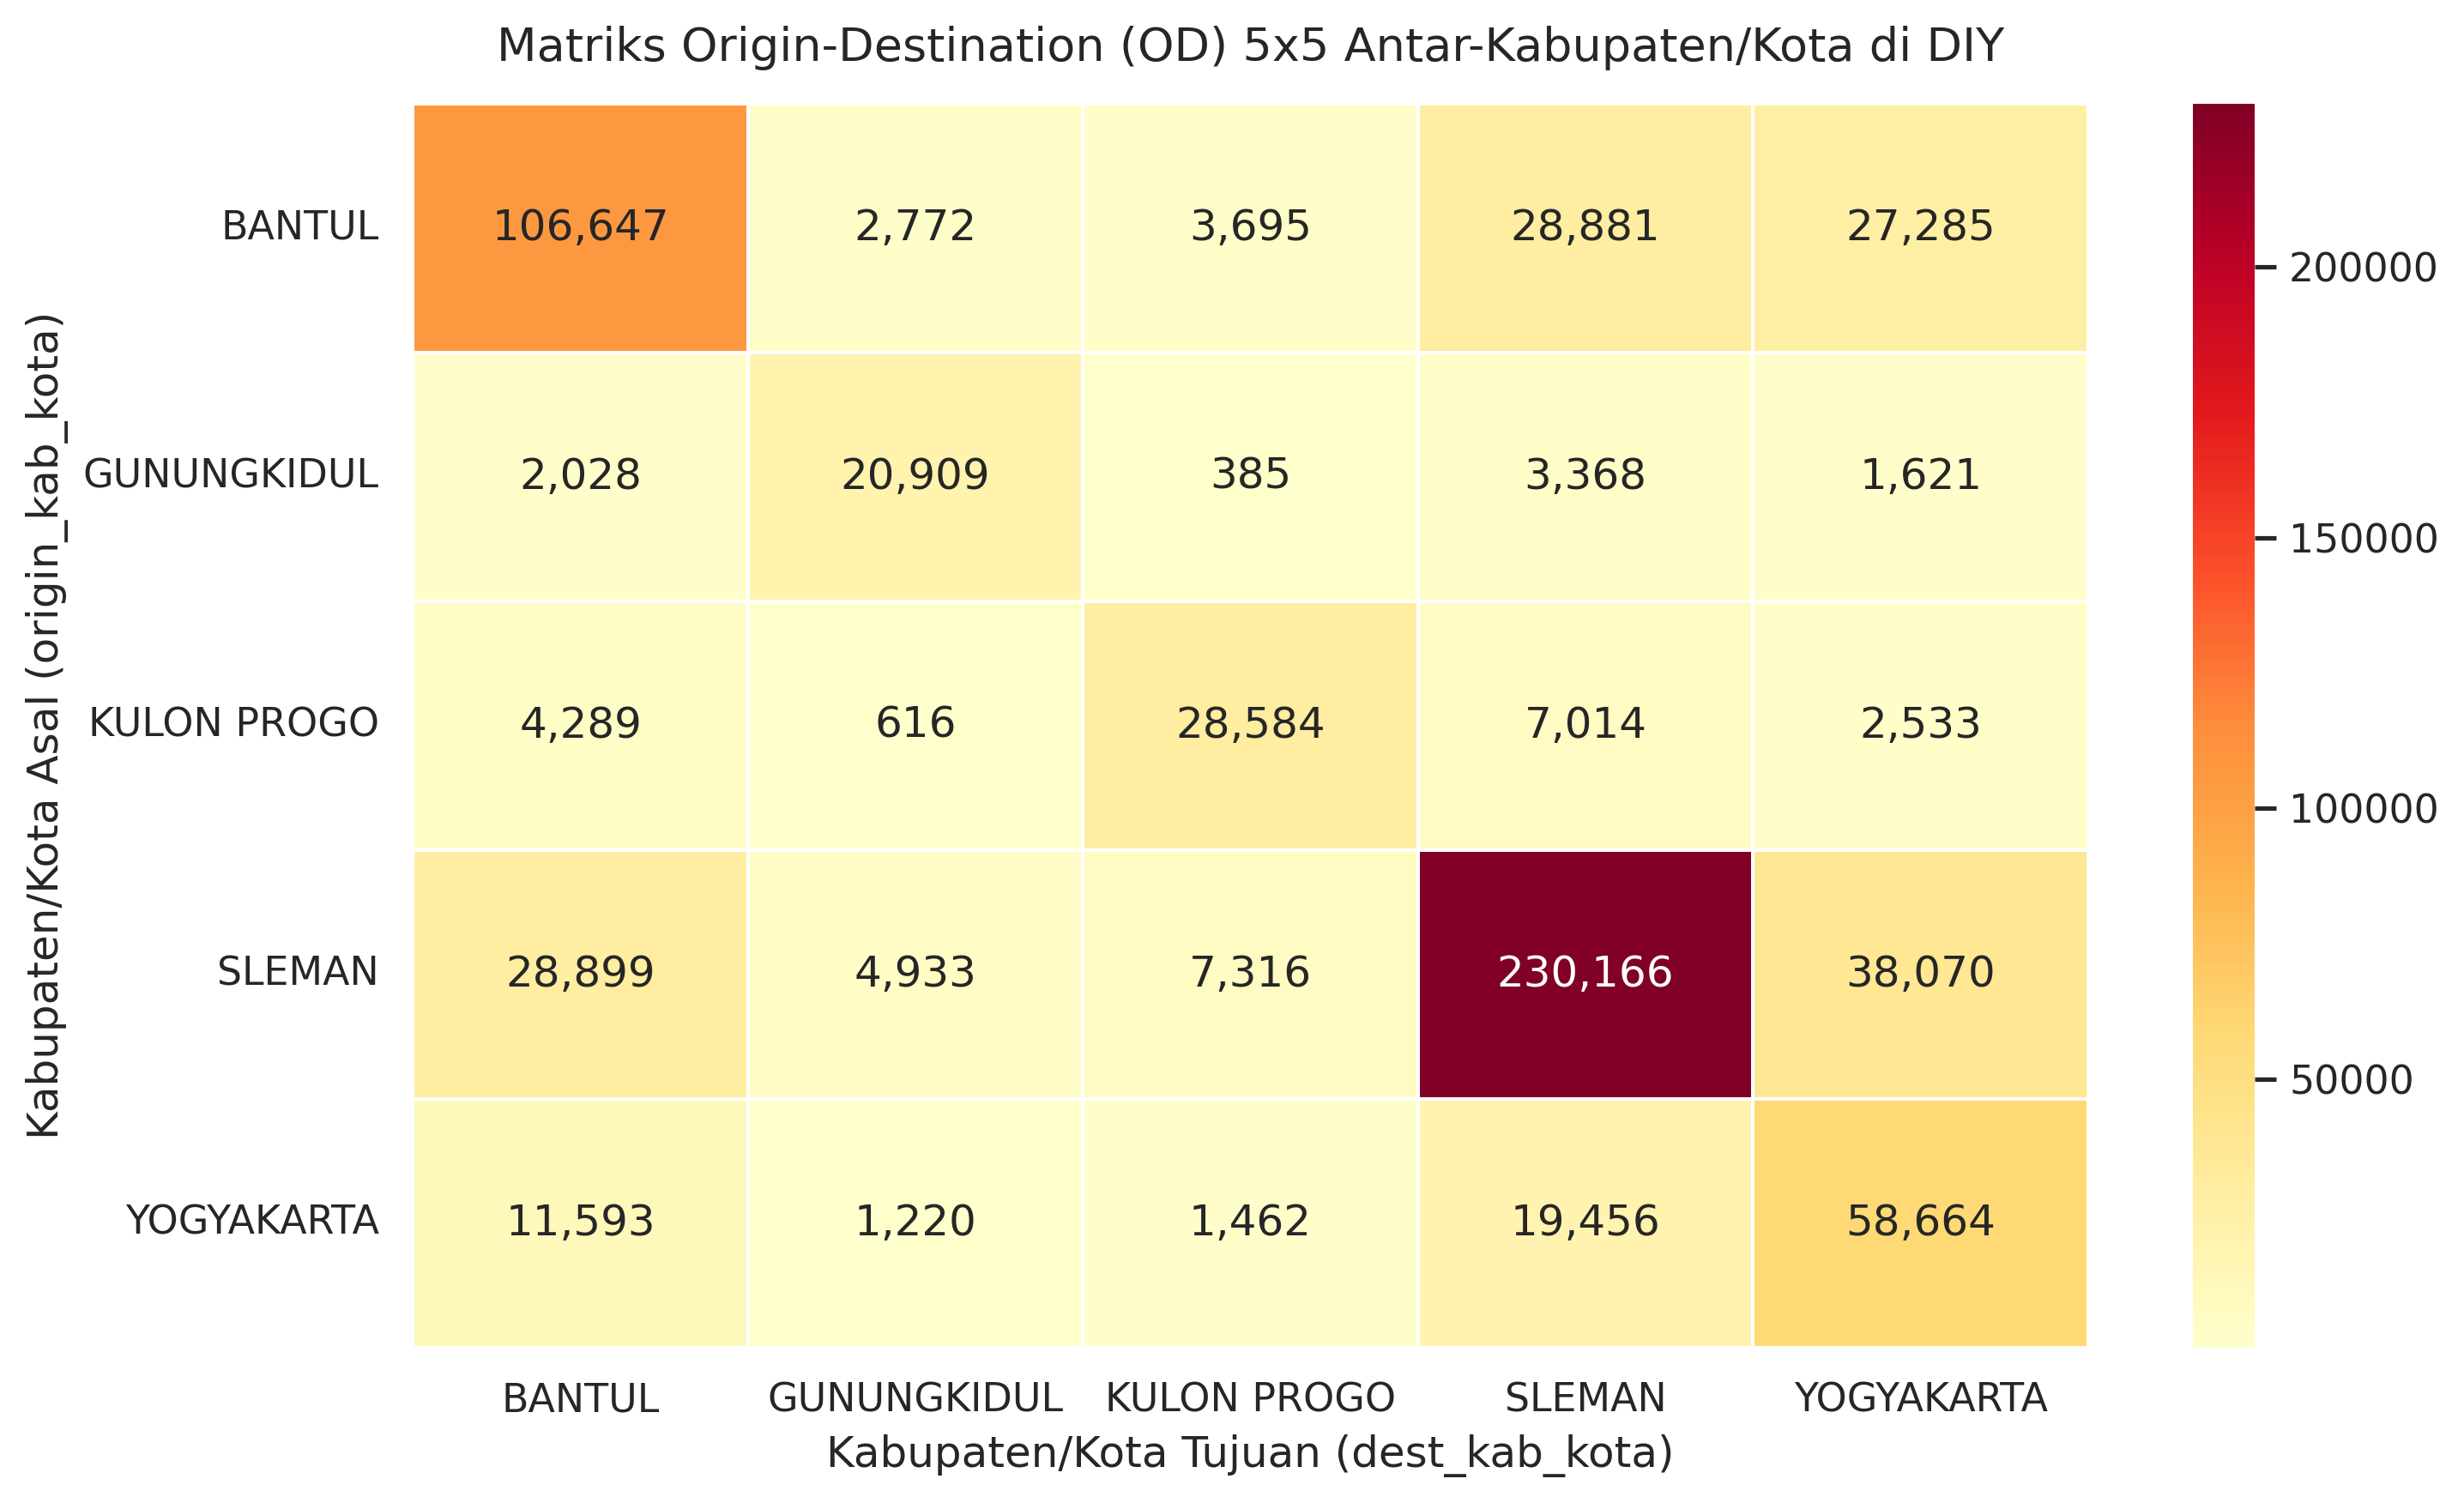

In [ ]:
od_kab_matrix = (
    df_od.groupby(["origin_kab_kota", "dest_kab_kota"])["n_maids"]
    .sum()
    .unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.heatmap(od_kab_matrix, annot=True, fmt=",.0f", cmap="YlOrRd", linewidths=0.5, ax=ax)
ax.set_title("Matriks Origin-Destination (OD) 5x5 Antar-Kabupaten/Kota di DIY", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota Tujuan (dest_kab_kota)")
ax.set_ylabel("Kabupaten/Kota Asal (origin_kab_kota)")
plt.tight_layout()
plt.savefig("figures/05a_heatmap_od_5x5_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

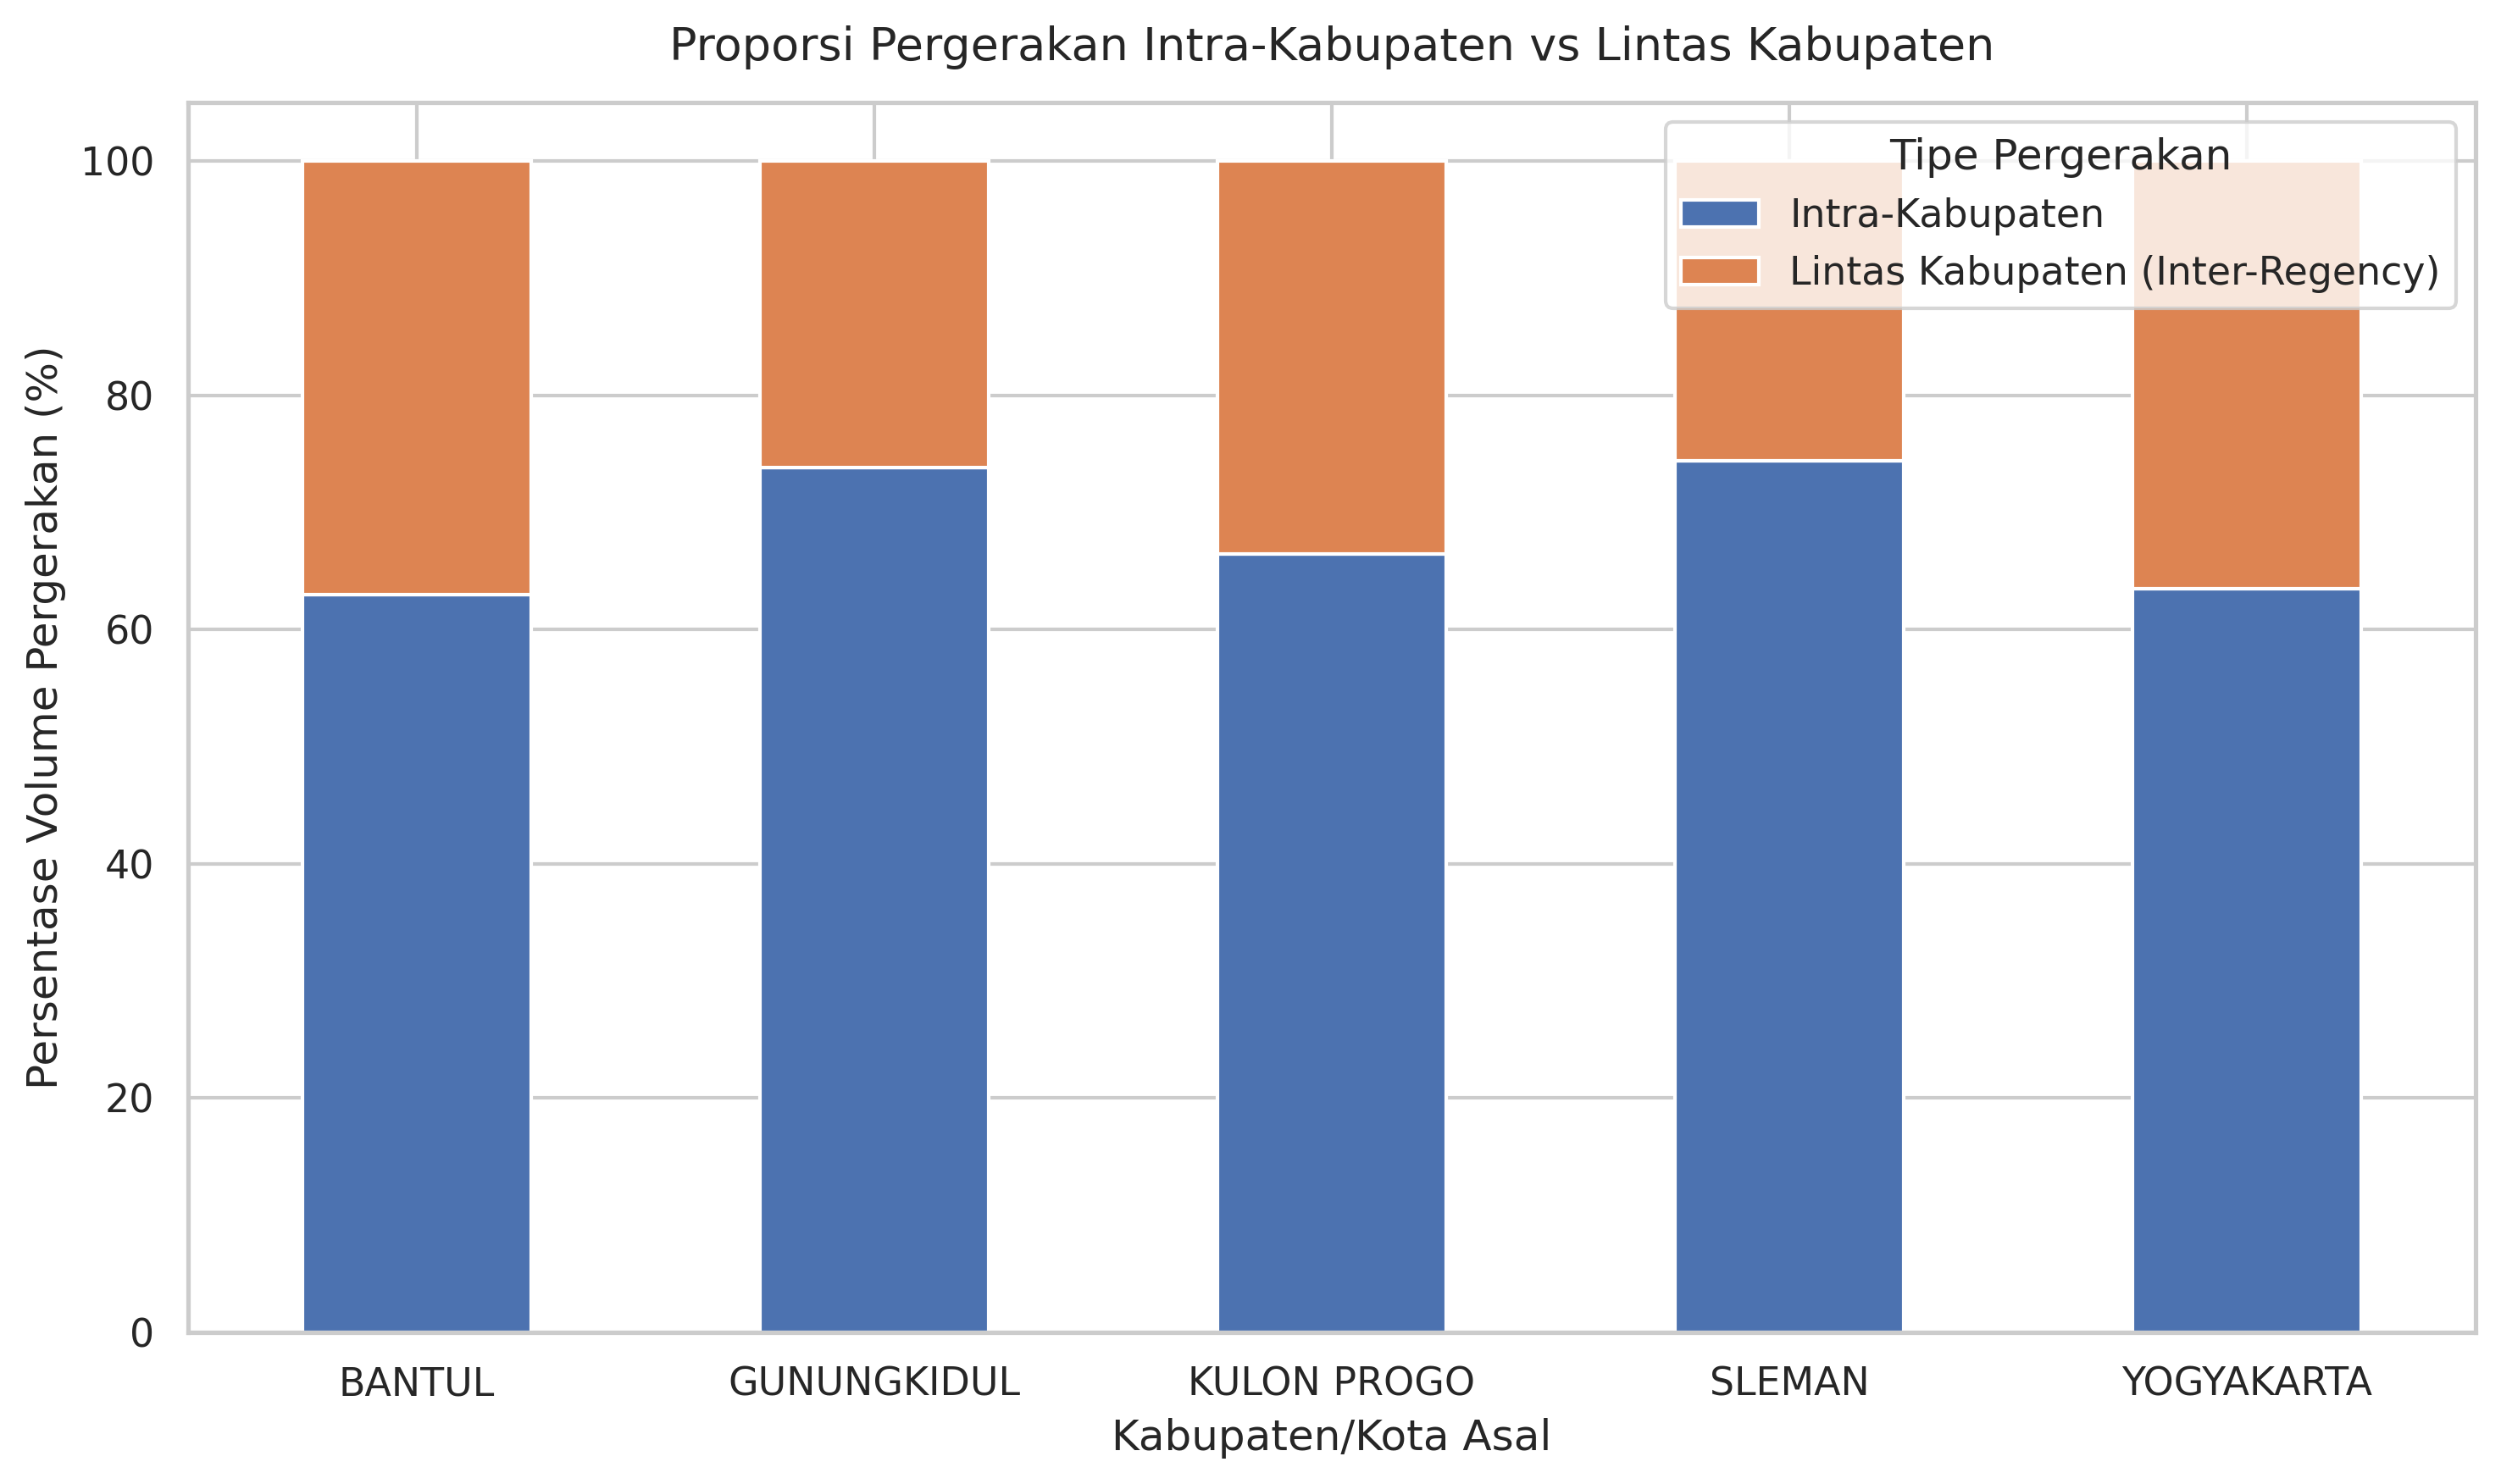

In [ ]:
df_od["tipe_pergerakan"] = np.where(
    df_od["origin_kab_kota"] == df_od["dest_kab_kota"],
    "Intra-Kabupaten",
    "Lintas Kabupaten (Inter-Regency)",
)
prop_df = (
    df_od.groupby(["origin_kab_kota", "tipe_pergerakan"])["n_maids"]
    .sum()
    .unstack(fill_value=0)
)
prop_pct = prop_df.div(prop_df.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
prop_pct.plot(kind="bar", stacked=True, color=["#4c72b0", "#dd8452"], ax=ax)
ax.set_title("Proporsi Pergerakan Intra-Kabupaten vs Lintas Kabupaten", fontsize=13, pad=12)
ax.set_xlabel("Kabupaten/Kota Asal")
ax.set_ylabel("Persentase Volume Pergerakan (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Tipe Pergerakan", frameon=True)
plt.tight_layout()
plt.savefig("figures/05b_proporsi_intra_vs_inter_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 6: Analisis Koridor Komuter Mikro Lintas-Kapanewon

Memfilter pergerakan lintas kapanewon (`origin_code != dest_code`) untuk mengidentifikasi 20 rute komuter tersibuk serta membandingkan 10 kapanewon pengirim komuter terbesar dengan 10 kapanewon penerima kunjungan terbesar.

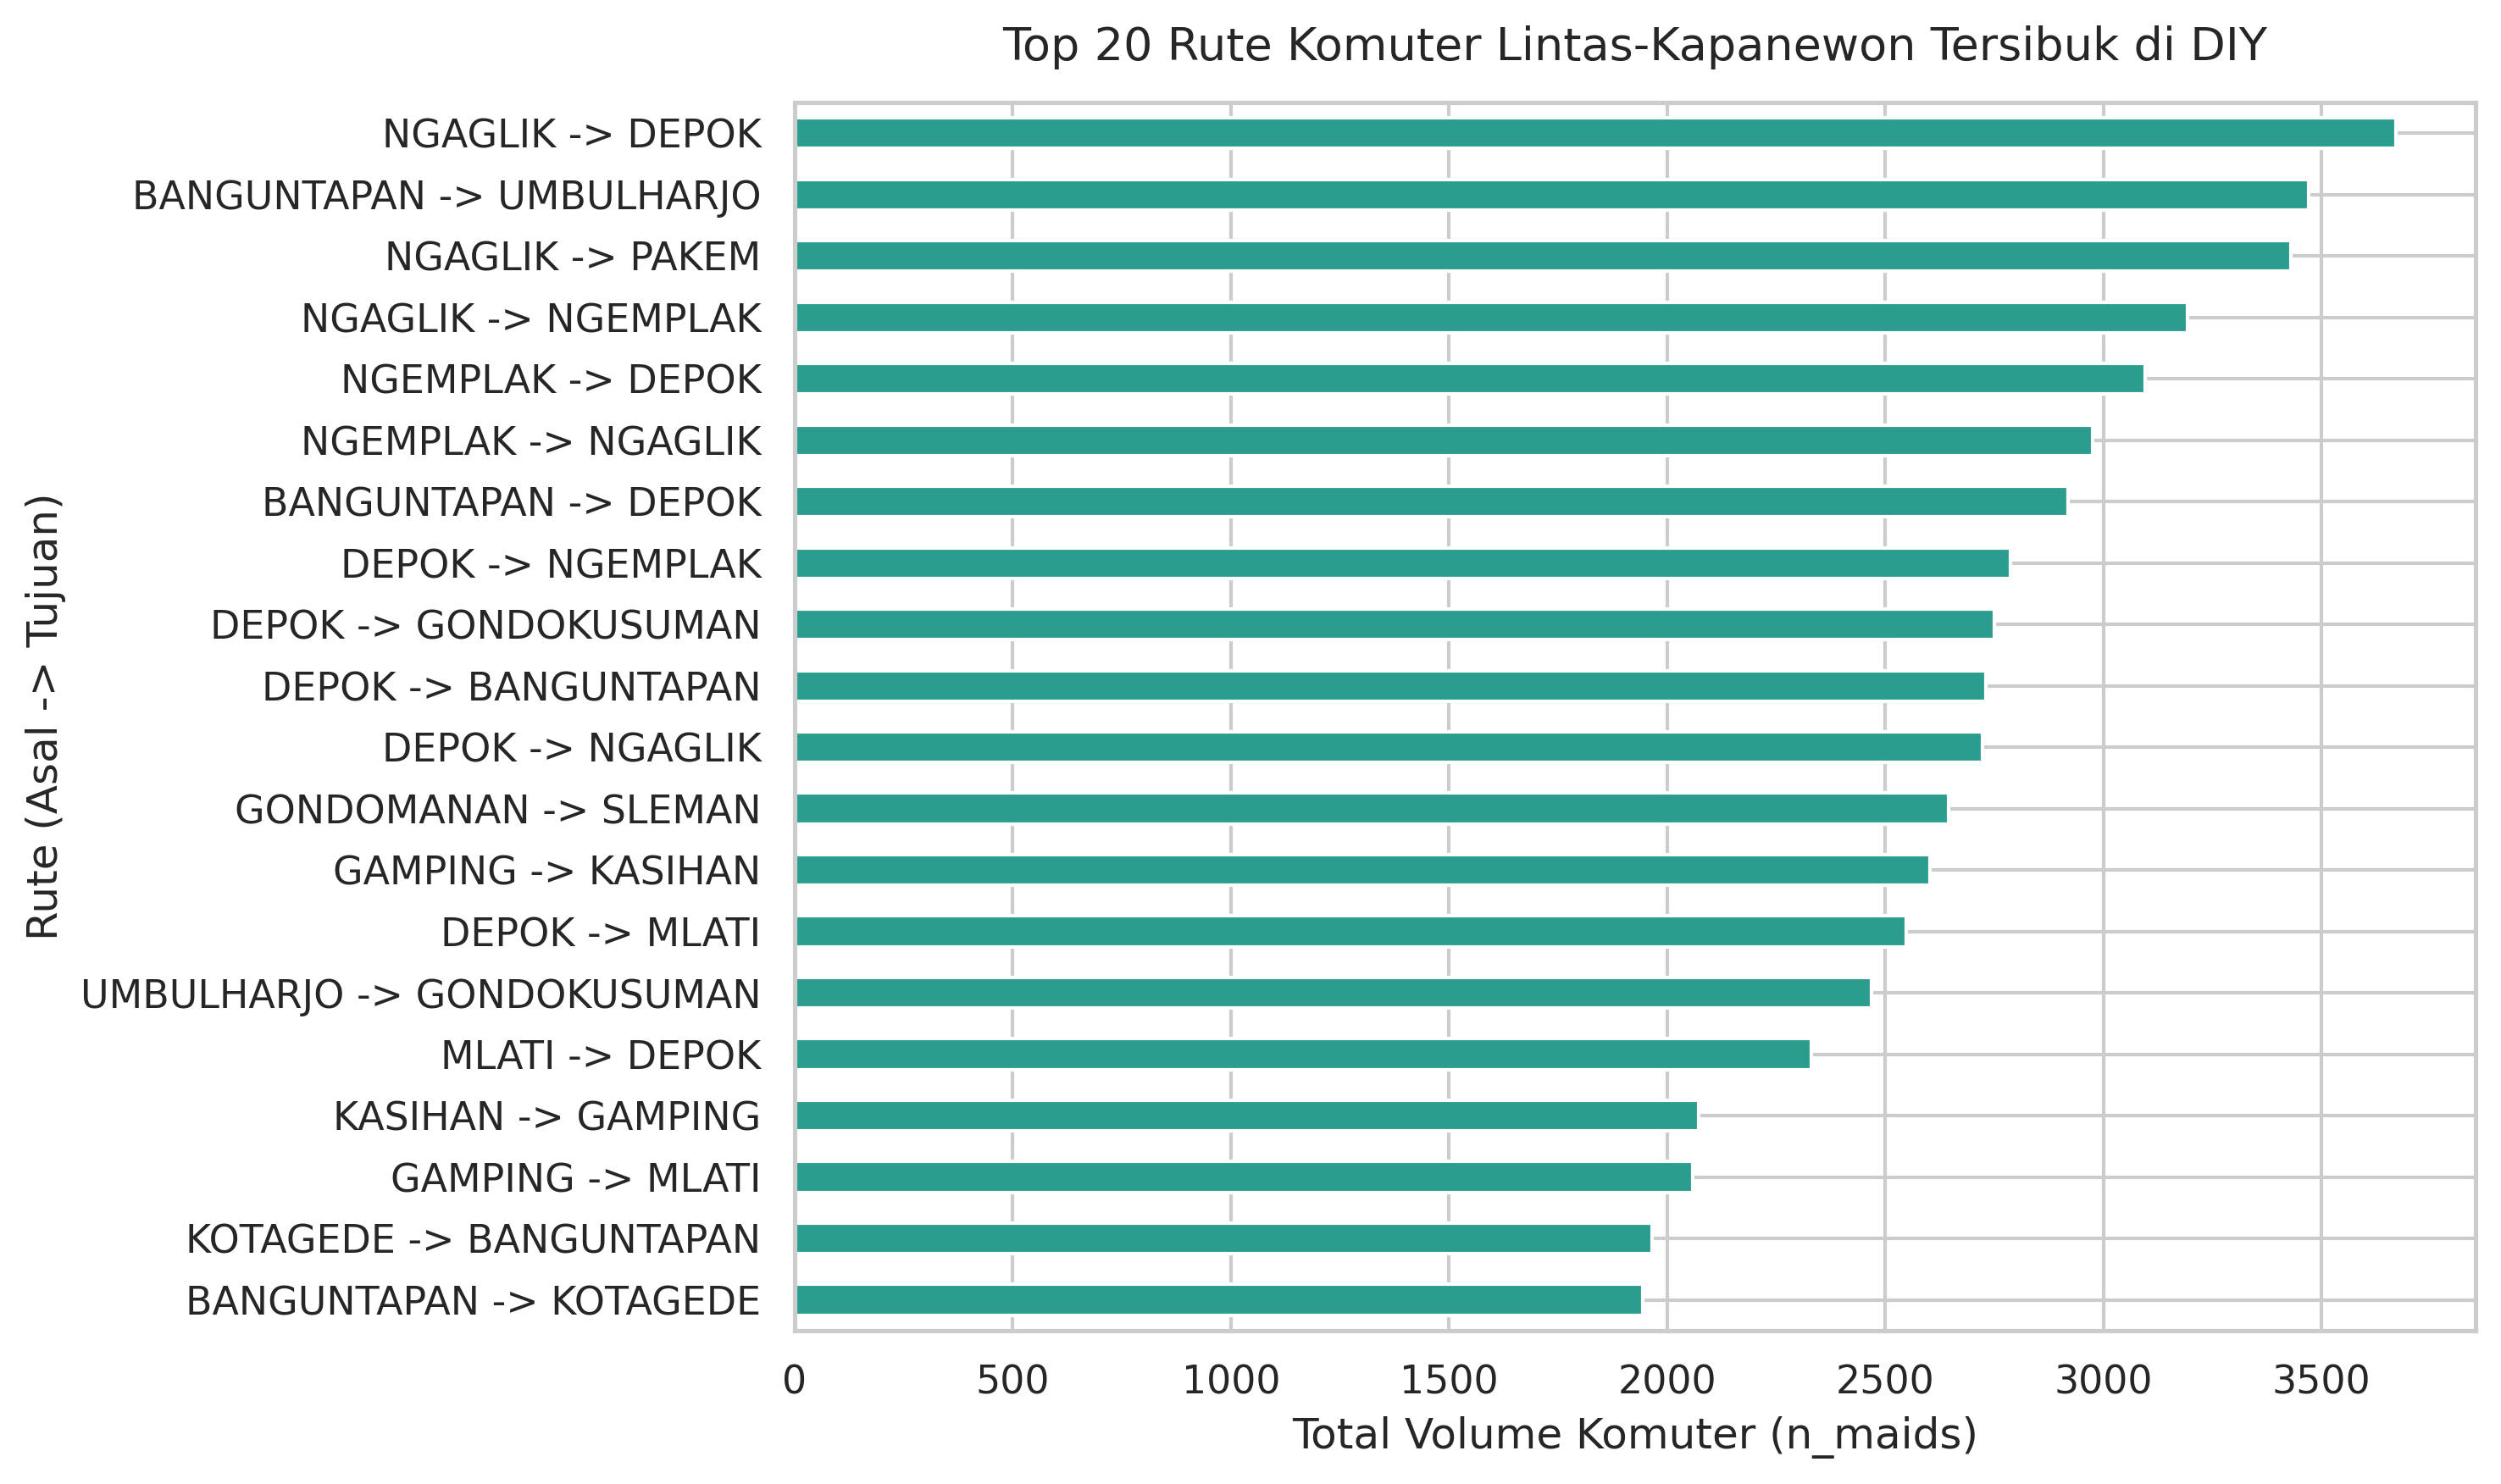

In [ ]:
df_od_lintas = df_od[df_od["origin_code"] != df_od["dest_code"]].copy()
df_od_lintas["rute"] = df_od_lintas["origin_kapanewon"] + " -> " + df_od_lintas["dest_kapanewon"]

top20_rute = (
    df_od_lintas.groupby("rute")["n_maids"]
    .sum()
    .nlargest(20)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
top20_rute.plot(kind="barh", color="#2a9d8f", ax=ax)
ax.set_title("Top 20 Rute Komuter Lintas-Kapanewon Tersibuk di DIY", fontsize=13, pad=12)
ax.set_xlabel("Total Volume Komuter (n_maids)")
ax.set_ylabel("Rute (Asal -> Tujuan)")
plt.tight_layout()
plt.savefig("figures/06a_top20_rute_lintas_kapanewon.png", dpi=300, bbox_inches="tight")
plt.show()

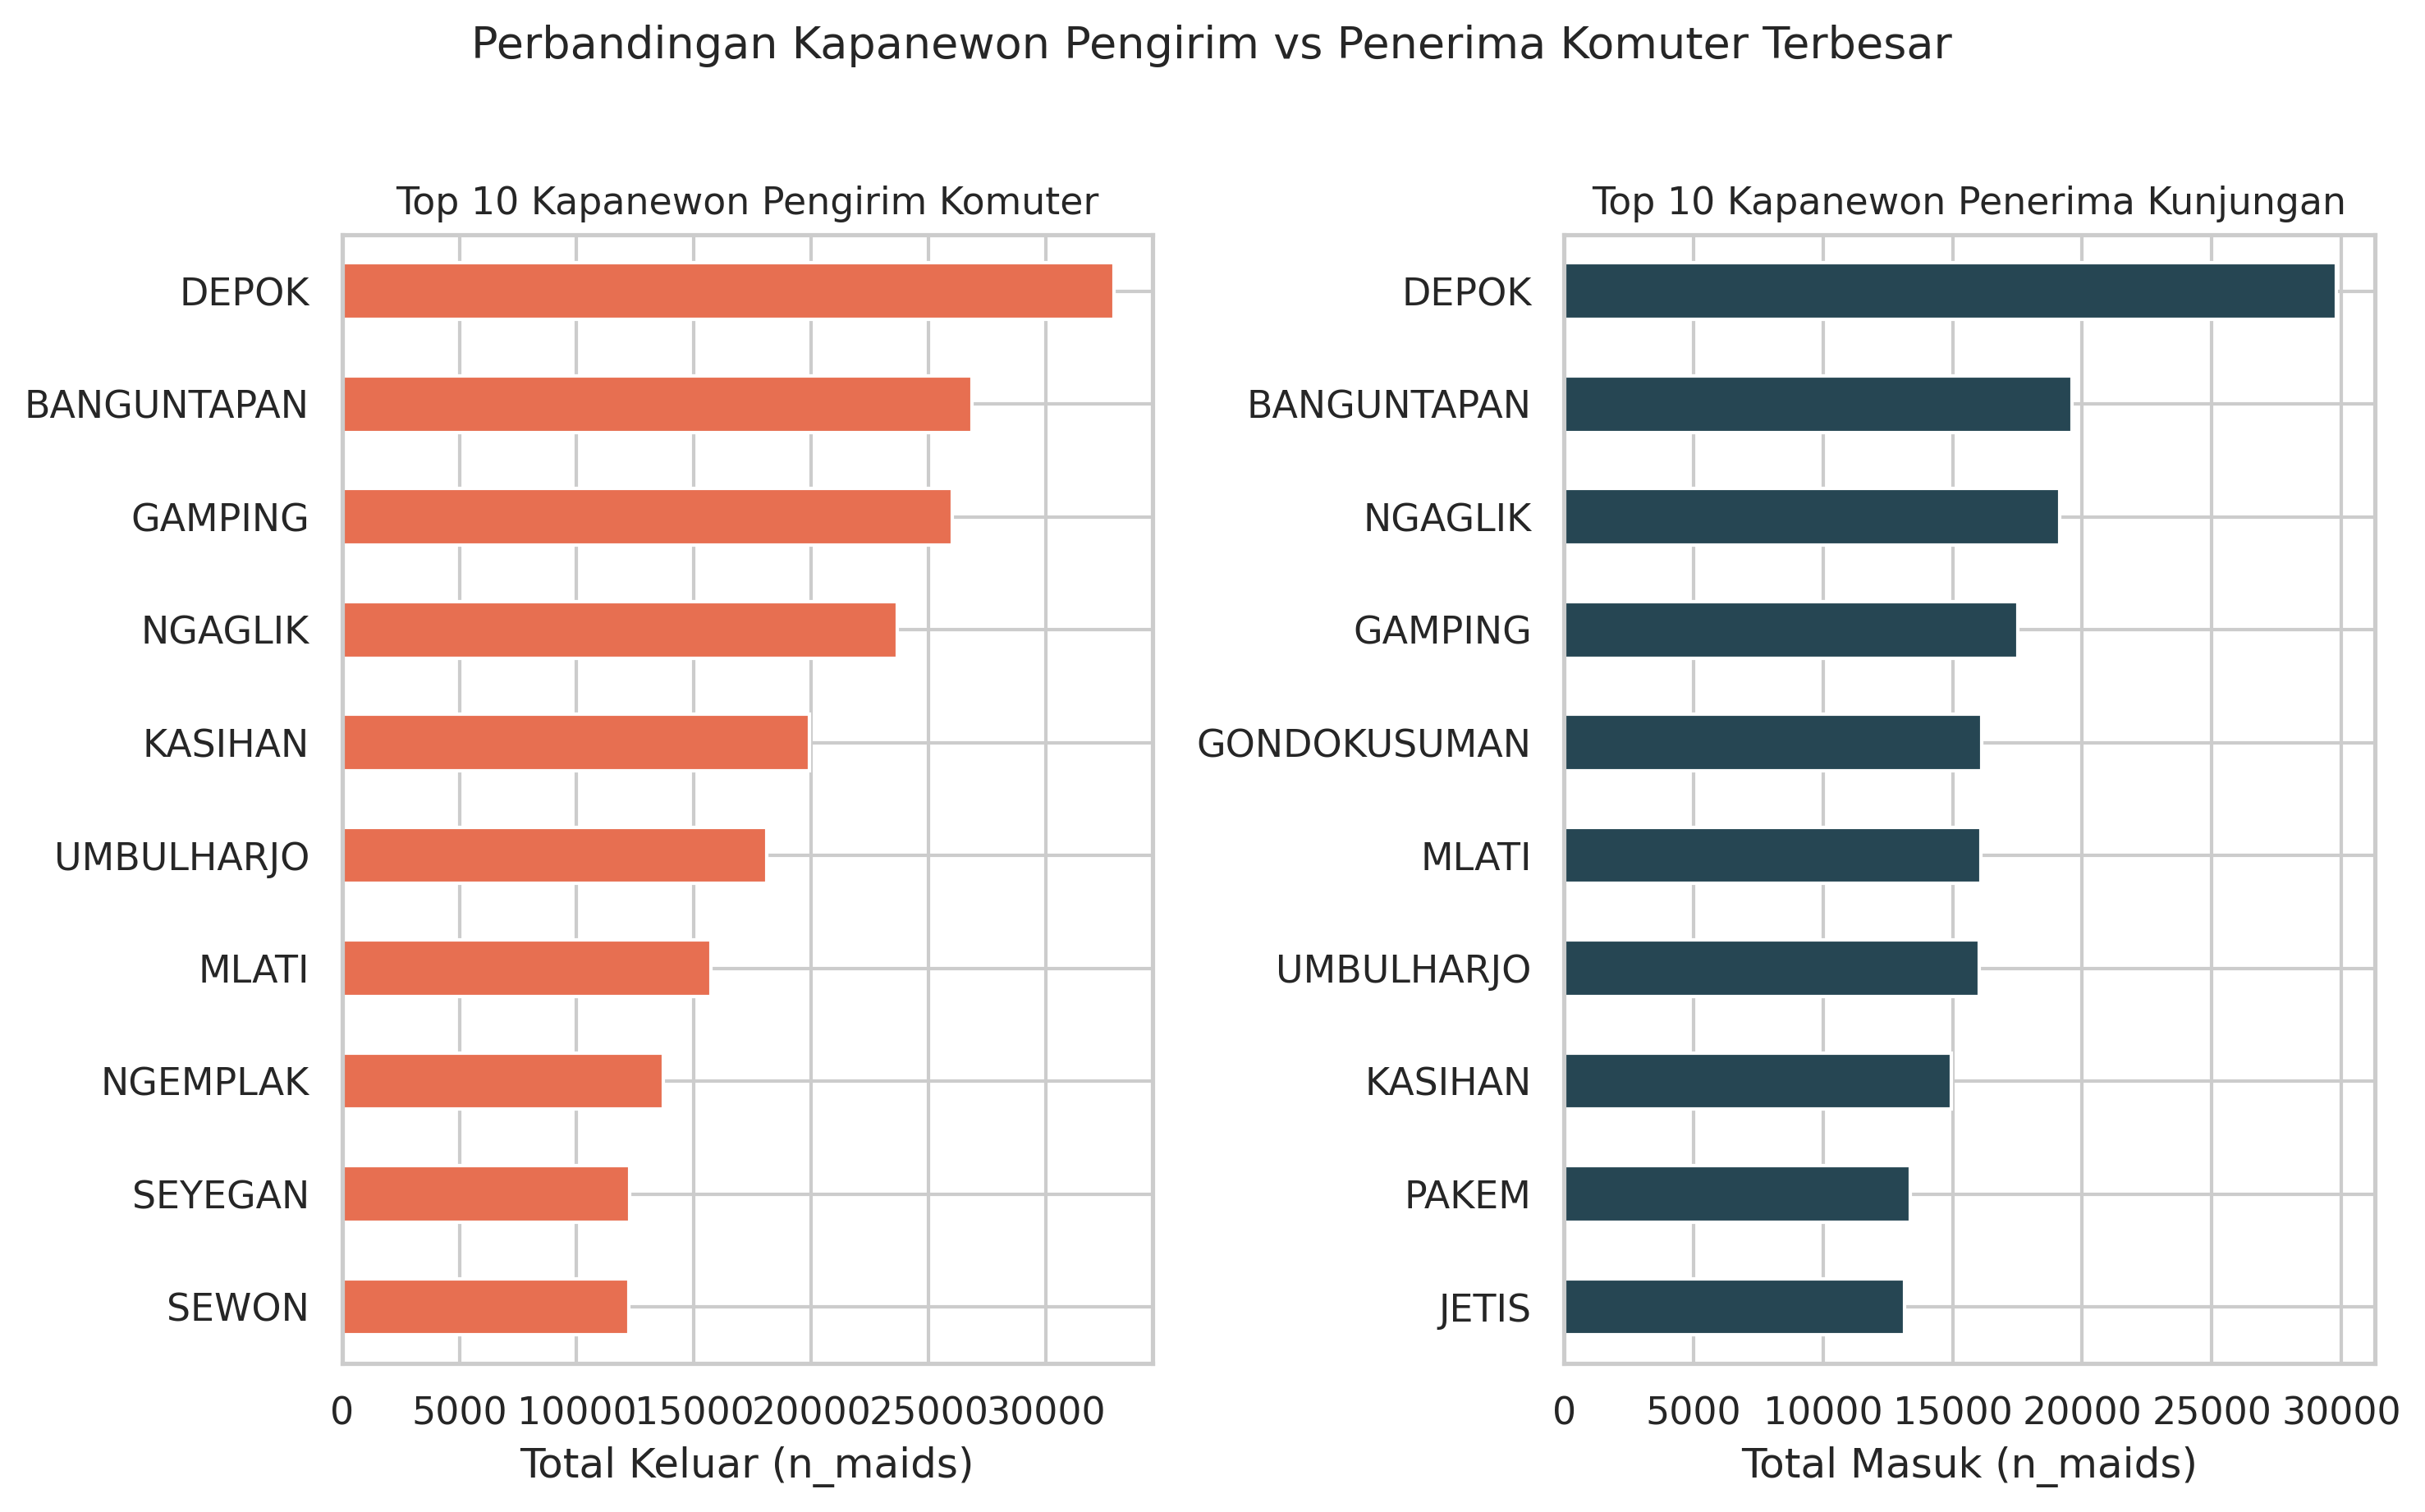

In [ ]:
top10_pengirim = df_od_lintas.groupby("origin_kapanewon")["n_maids"].sum().nlargest(10).sort_values()
top10_penerima = df_od_lintas.groupby("dest_kapanewon")["n_maids"].sum().nlargest(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(10, 6), dpi=300)
top10_pengirim.plot(kind="barh", color="#e76f51", ax=axes[0])
axes[0].set_title("Top 10 Kapanewon Pengirim Komuter", fontsize=11)
axes[0].set_xlabel("Total Keluar (n_maids)")
axes[0].set_ylabel("")

top10_penerima.plot(kind="barh", color="#264653", ax=axes[1])
axes[1].set_title("Top 10 Kapanewon Penerima Kunjungan", fontsize=11)
axes[1].set_xlabel("Total Masuk (n_maids)")
axes[1].set_ylabel("")

fig.suptitle("Perbandingan Kapanewon Pengirim vs Penerima Komuter Terbesar", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/06b_top10_pengirim_vs_penerima.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 7: Pemodelan Jaringan Graf (Network Centrality) 78 Kapanewon

Membangun graf berarah (*directed graph*) menggunakan `networkx` dengan 78 kapanewon sebagai simpul dan total `n_maids` sebagai bobot garis, lalu menghitung *Weighted In-Degree*, *Weighted Out-Degree*, dan *PageRank Centrality*.

In [ ]:
edge_agg = (
    df_od_lintas.groupby(["origin_kapanewon", "dest_kapanewon"])["n_maids"]
    .sum()
    .reset_index()
)

G = nx.DiGraph()
for _, row in edge_agg.iterrows():
    G.add_edge(row["origin_kapanewon"], row["dest_kapanewon"], weight=row["n_maids"])

in_deg = dict(G.in_degree(weight="weight"))
out_deg = dict(G.out_degree(weight="weight"))
pagerank = nx.pagerank(G, weight="weight")

centrality_df = pd.DataFrame({
    "kapanewon": list(G.nodes()),
    "weighted_in_degree": [in_deg[n] for n in G.nodes()],
    "weighted_out_degree": [out_deg[n] for n in G.nodes()],
    "pagerank": [pagerank[n] for n in G.nodes()],
}).sort_values("pagerank", ascending=False)

centrality_df.head(15)

,kapanewon,weighted_in_degree,weighted_out_degree,pagerank
4,DEPOK,29796,32890,0.064355
1,BANGUNTAPAN,19612,26847,0.045326
21,NGAGLIK,19134,23649,0.041029
35,UMBULHARJO,16028,18096,0.038379
6,GAMPING,17506,26005,0.037497
8,GONDOKUSUMAN,16120,7491,0.036204
13,KASIHAN,14949,19910,0.034852
20,MLATI,16075,15716,0.032998
11,JETIS,13145,9604,0.031510
9,GONDOMANAN,10899,8760,0.029000


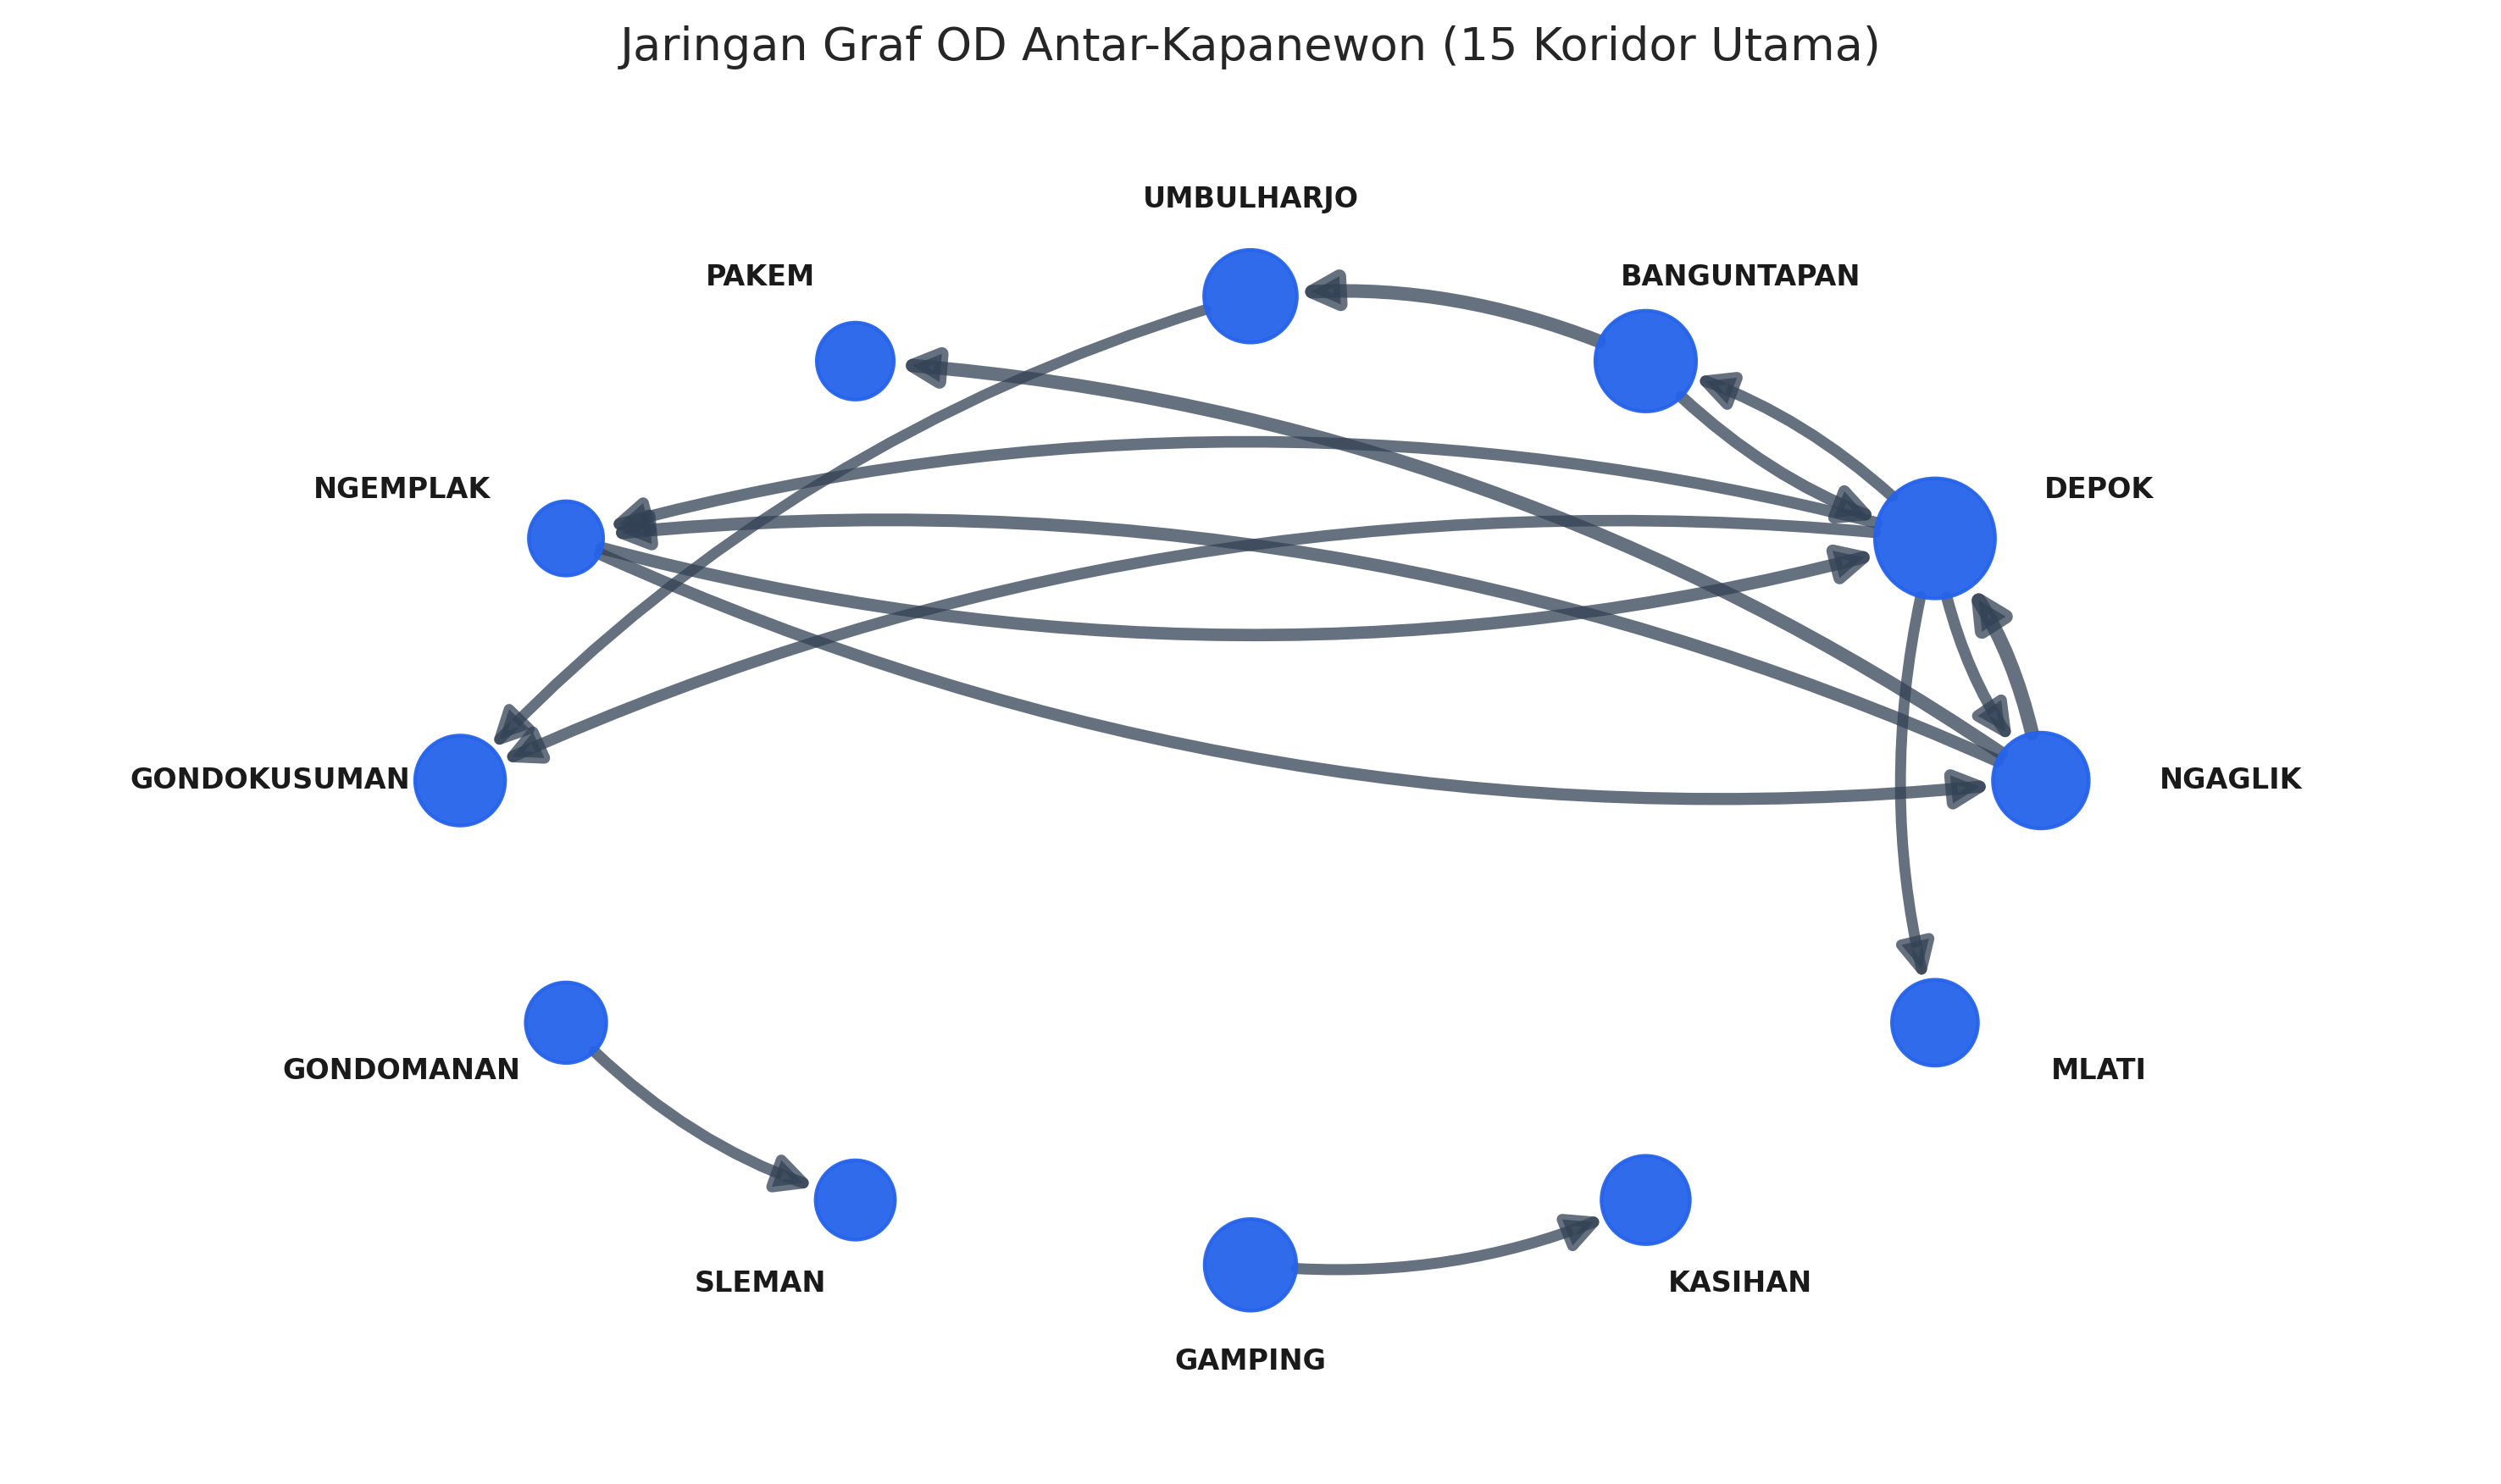

In [ ]:
top_edges = edge_agg.nlargest(15, "n_maids")
G_vis = nx.DiGraph()
for _, row in top_edges.iterrows():
    G_vis.add_edge(row["origin_kapanewon"], row["dest_kapanewon"], weight=row["n_maids"])

pos = nx.circular_layout(G_vis)
node_sizes = [pagerank.get(n, 0.005) * 18000 for n in G_vis.nodes()]
max_w = top_edges["n_maids"].max()
edge_widths = [1.0 + 3.0 * (d["weight"] / max_w) for _, _, d in G_vis.edges(data=True)]

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
nx.draw_networkx_nodes(G_vis, pos, node_size=node_sizes, node_color="#2563eb", alpha=0.95, ax=ax)
nx.draw_networkx_edges(
    G_vis,
    pos,
    node_size=node_sizes,
    width=edge_widths,
    alpha=0.75,
    edge_color="#334155",
    arrows=True,
    arrowstyle="-|>",
    arrowsize=20,
    min_target_margin=12,
    connectionstyle="arc3,rad=0.14",
    ax=ax,
)

label_pos = {k: (v[0] * 1.24, v[1] * 1.20) for k, v in pos.items()}
nx.draw_networkx_labels(G_vis, label_pos, font_size=8, font_weight="bold", ax=ax)

ax.set_xlim(-1.55, 1.55)
ax.set_ylim(-1.40, 1.40)
ax.set_title("Jaringan Graf OD Antar-Kapanewon (15 Koridor Utama)", fontsize=13, pad=12)
ax.axis("off")
plt.tight_layout()
plt.savefig("figures/07a_network_graph_od.png", dpi=300, bbox_inches="tight")
plt.show()

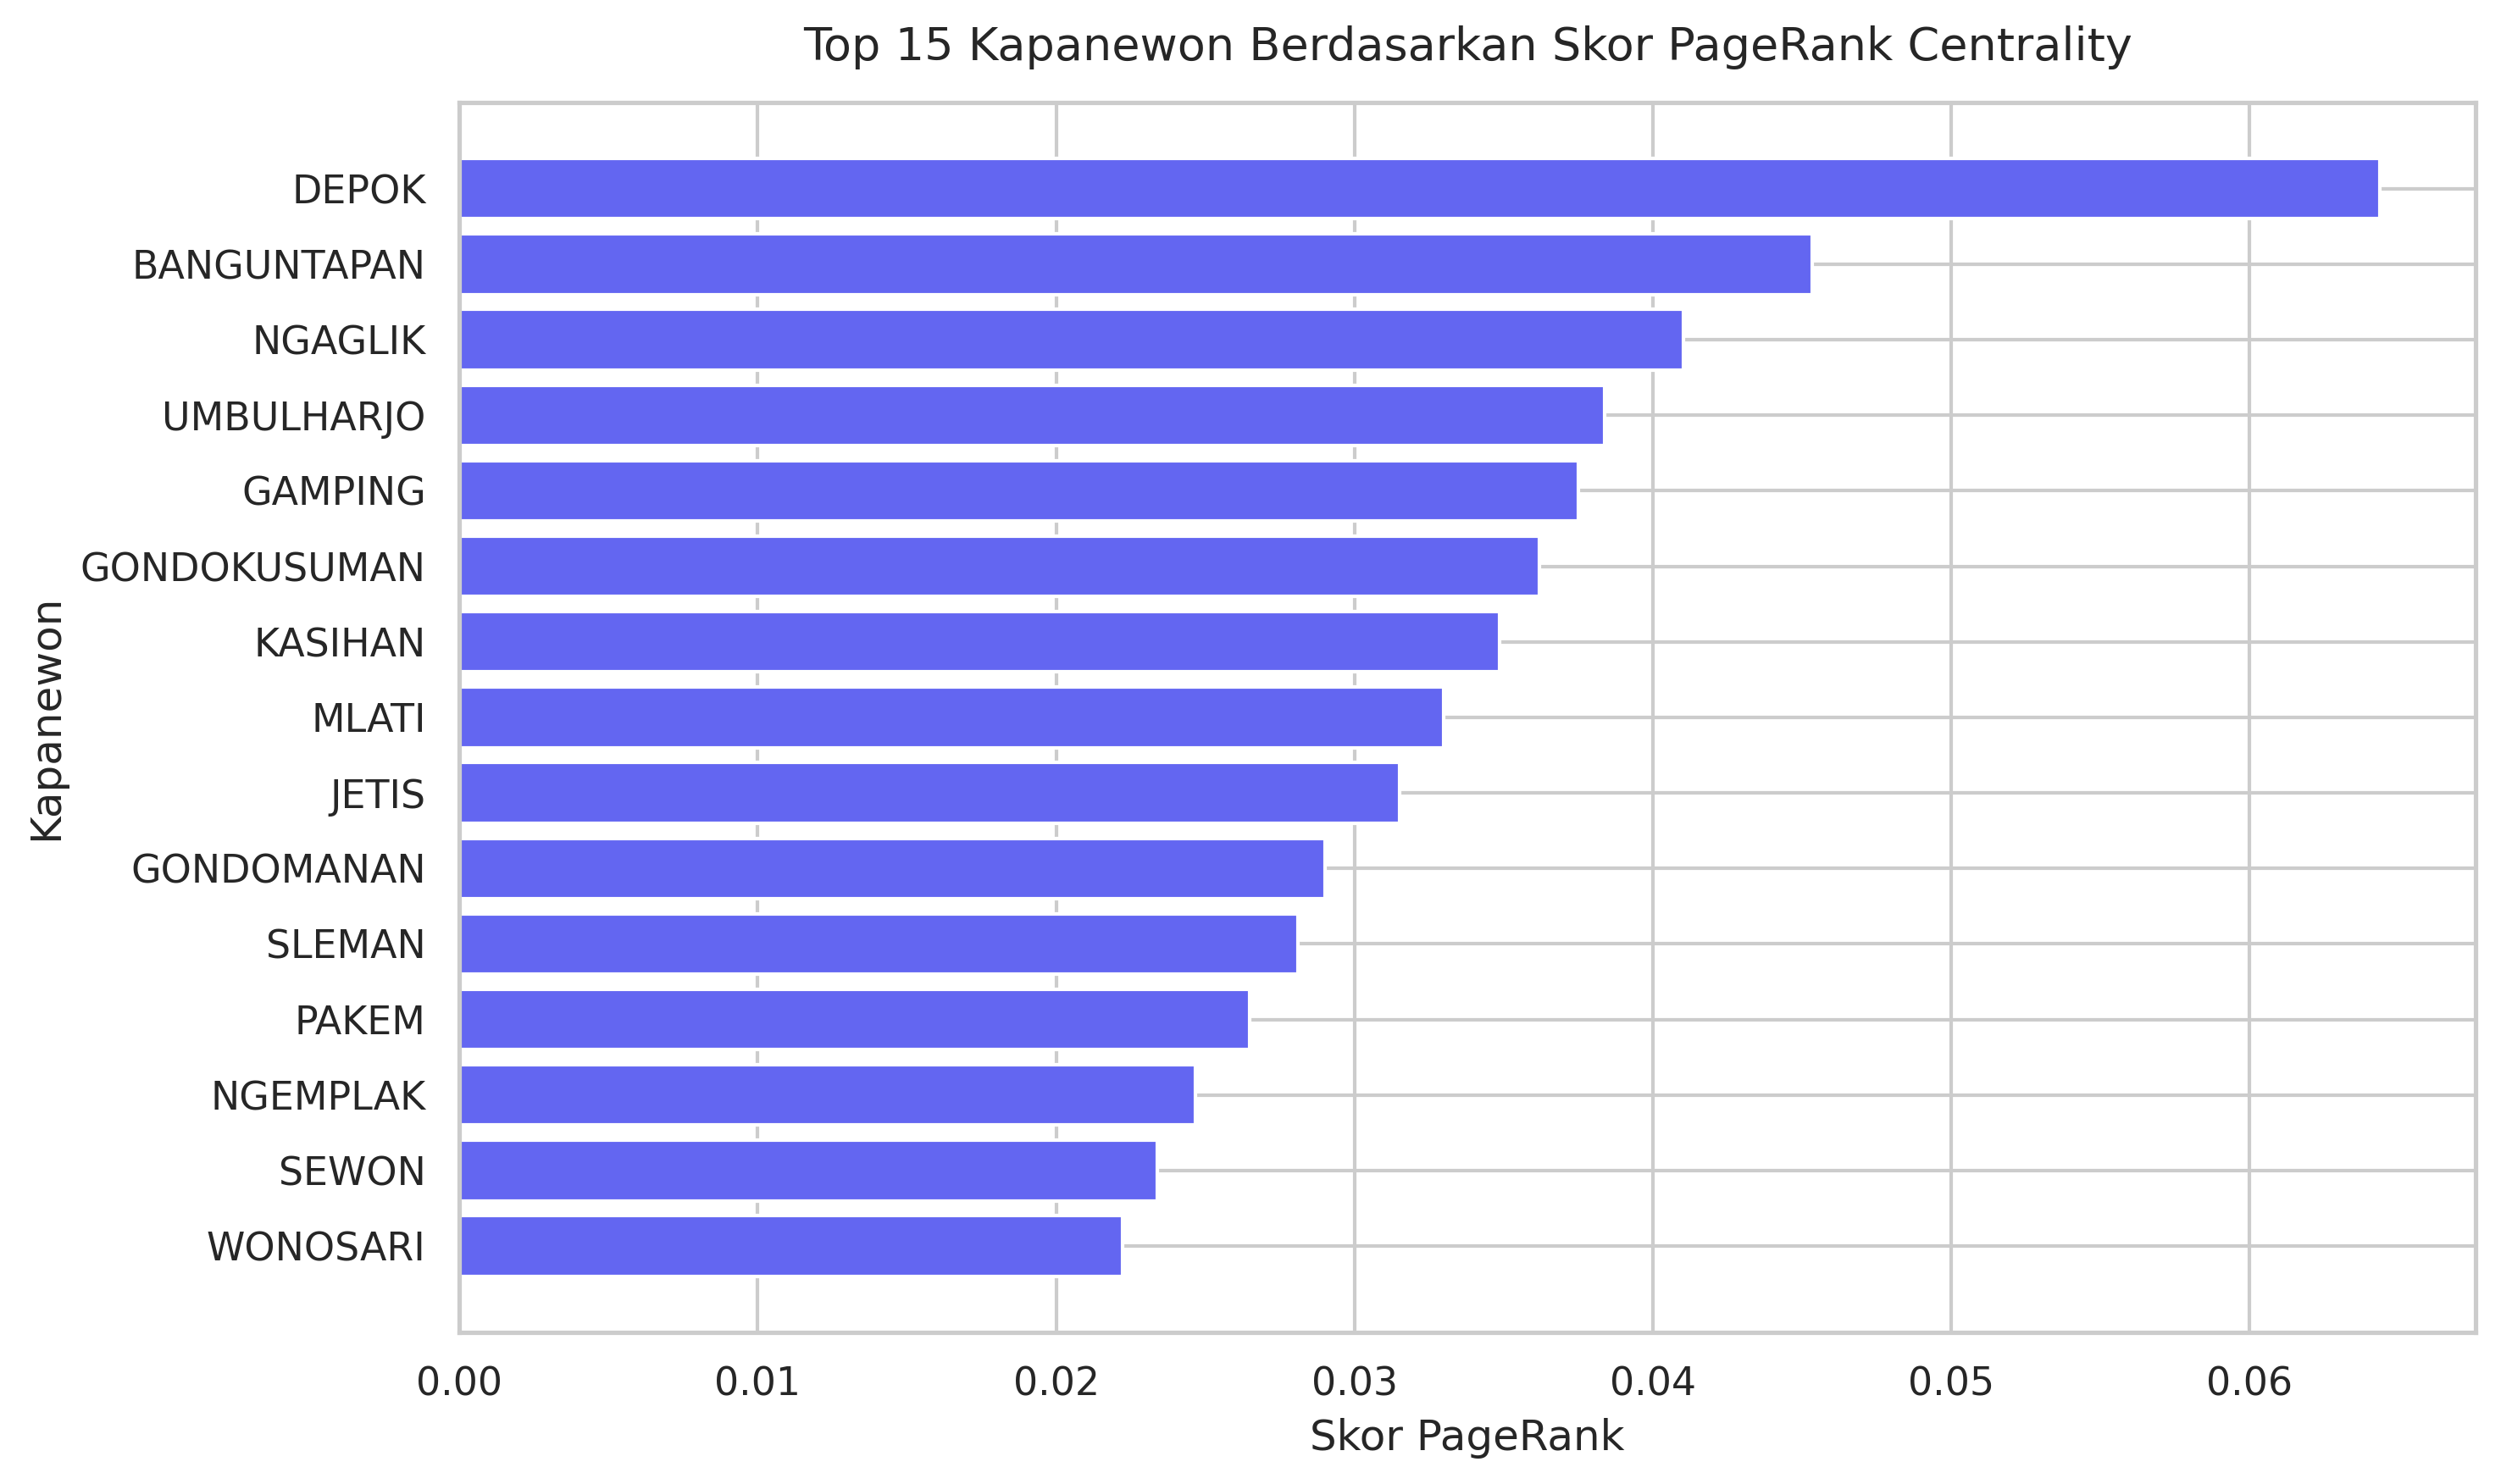

In [ ]:
top15_pr = centrality_df.head(15).sort_values("pagerank", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.barh(top15_pr["kapanewon"], top15_pr["pagerank"], color="#6366f1")
ax.set_title("Top 15 Kapanewon Berdasarkan Skor PageRank Centrality", fontsize=13, pad=12)
ax.set_xlabel("Skor PageRank")
ax.set_ylabel("Kapanewon")
plt.tight_layout()
plt.savefig("figures/07b_top15_pagerank_kapanewon.png", dpi=300, bbox_inches="tight")
plt.show()

## Bagian 8: Tren Pergerakan Bulanan & Evaluasi Kualitas Data (`reduced_quality`)

Menganalisis evolusi volume aliran OD bulanan (`2021-12` hingga `2022-04`) per Kabupaten/Kota tujuan serta mengevaluasi dampak penanda `reduced_quality` pada periode Maret–April 2022 dibandingkan periode normal Desember 2021–Februari 2022.

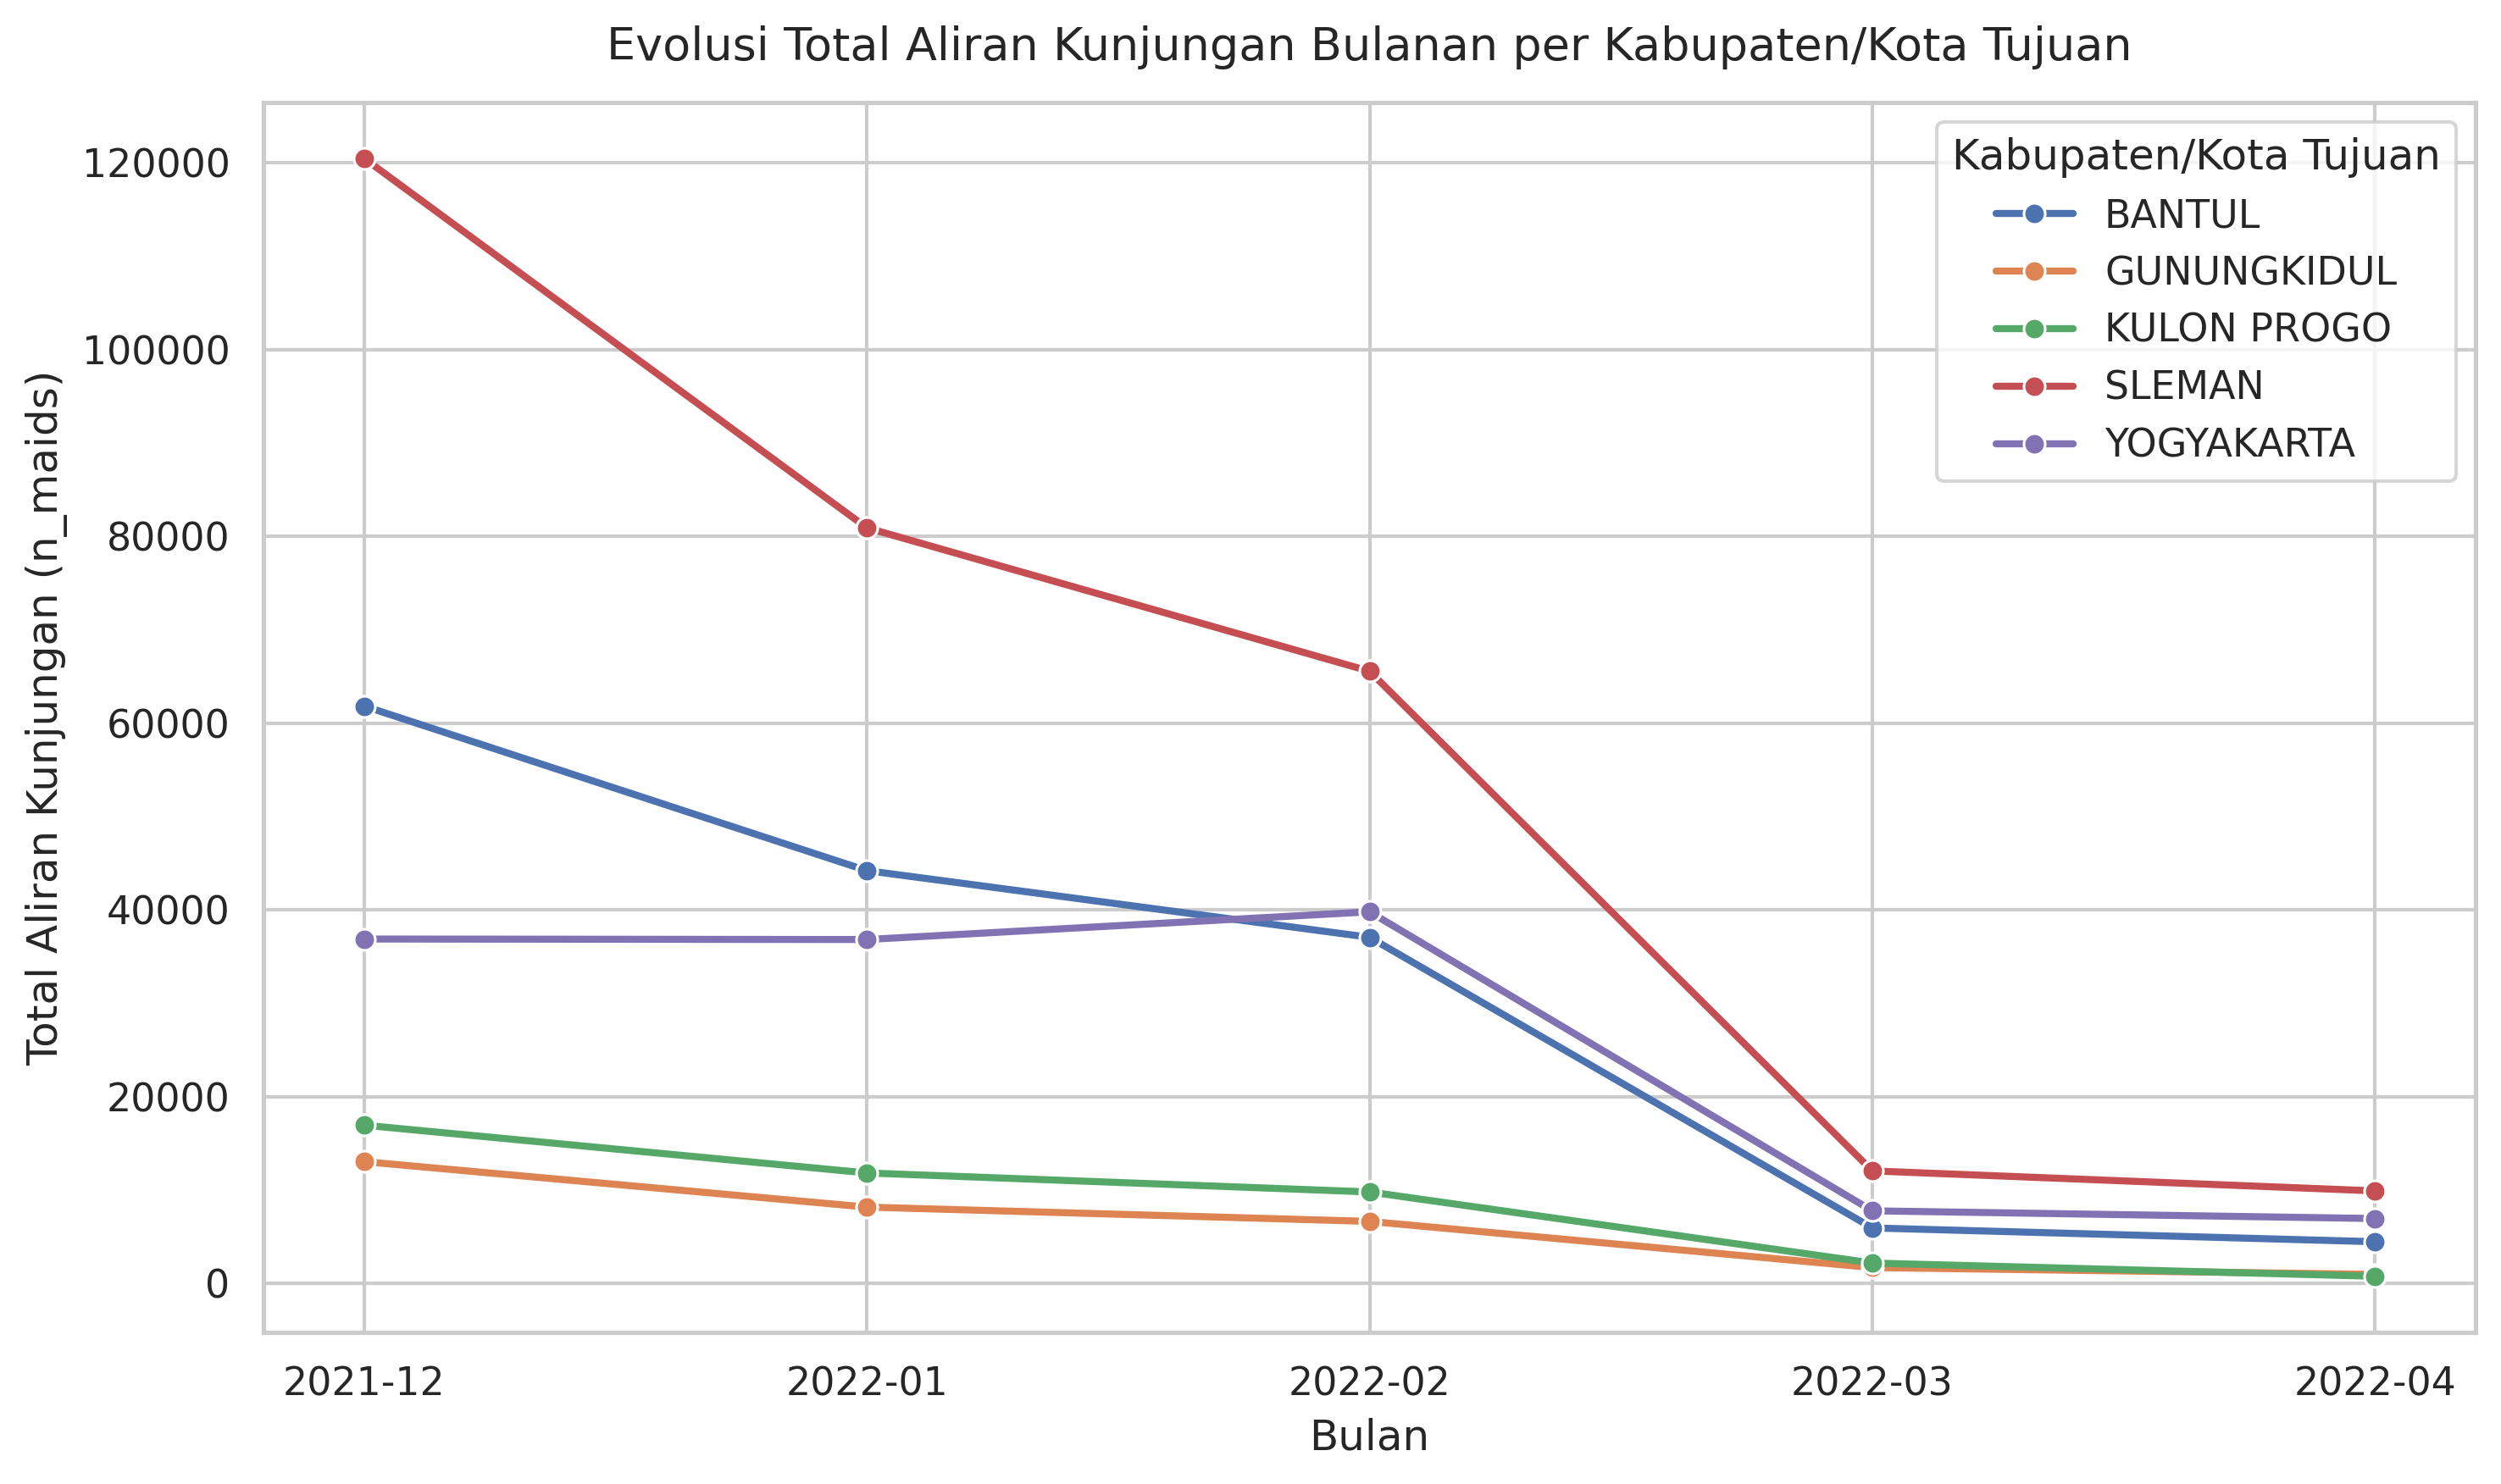

In [ ]:
df_od["month"] = df_od["month"].astype(str)
monthly_dest = (
    df_od.groupby(["month", "dest_kab_kota"])["n_maids"]
    .sum()
    .reset_index()
    .sort_values("month")
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
sns.lineplot(
    data=monthly_dest,
    x="month",
    y="n_maids",
    hue="dest_kab_kota",
    marker="o",
    linewidth=2,
    ax=ax,
)
ax.set_title("Evolusi Total Aliran Kunjungan Bulanan per Kabupaten/Kota Tujuan", fontsize=13, pad=12)
ax.set_xlabel("Bulan")
ax.set_ylabel("Total Aliran Kunjungan (n_maids)")
ax.legend(title="Kabupaten/Kota Tujuan", frameon=True)
plt.tight_layout()
plt.savefig("figures/08a_tren_bulanan_od_kabkota.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_572/797910642.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=quality_summary, x="status_kualitas", y="jumlah_rute_od", palette=["#2a9d8f", "#e76f51"], ax=axes[0])
/tmp/ipykernel_572/797910642.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=quality_summary, x="status_kualitas", y="rata_rata_maids", palette=["#2a9d8f", "#e76f51"], ax=axes[1])


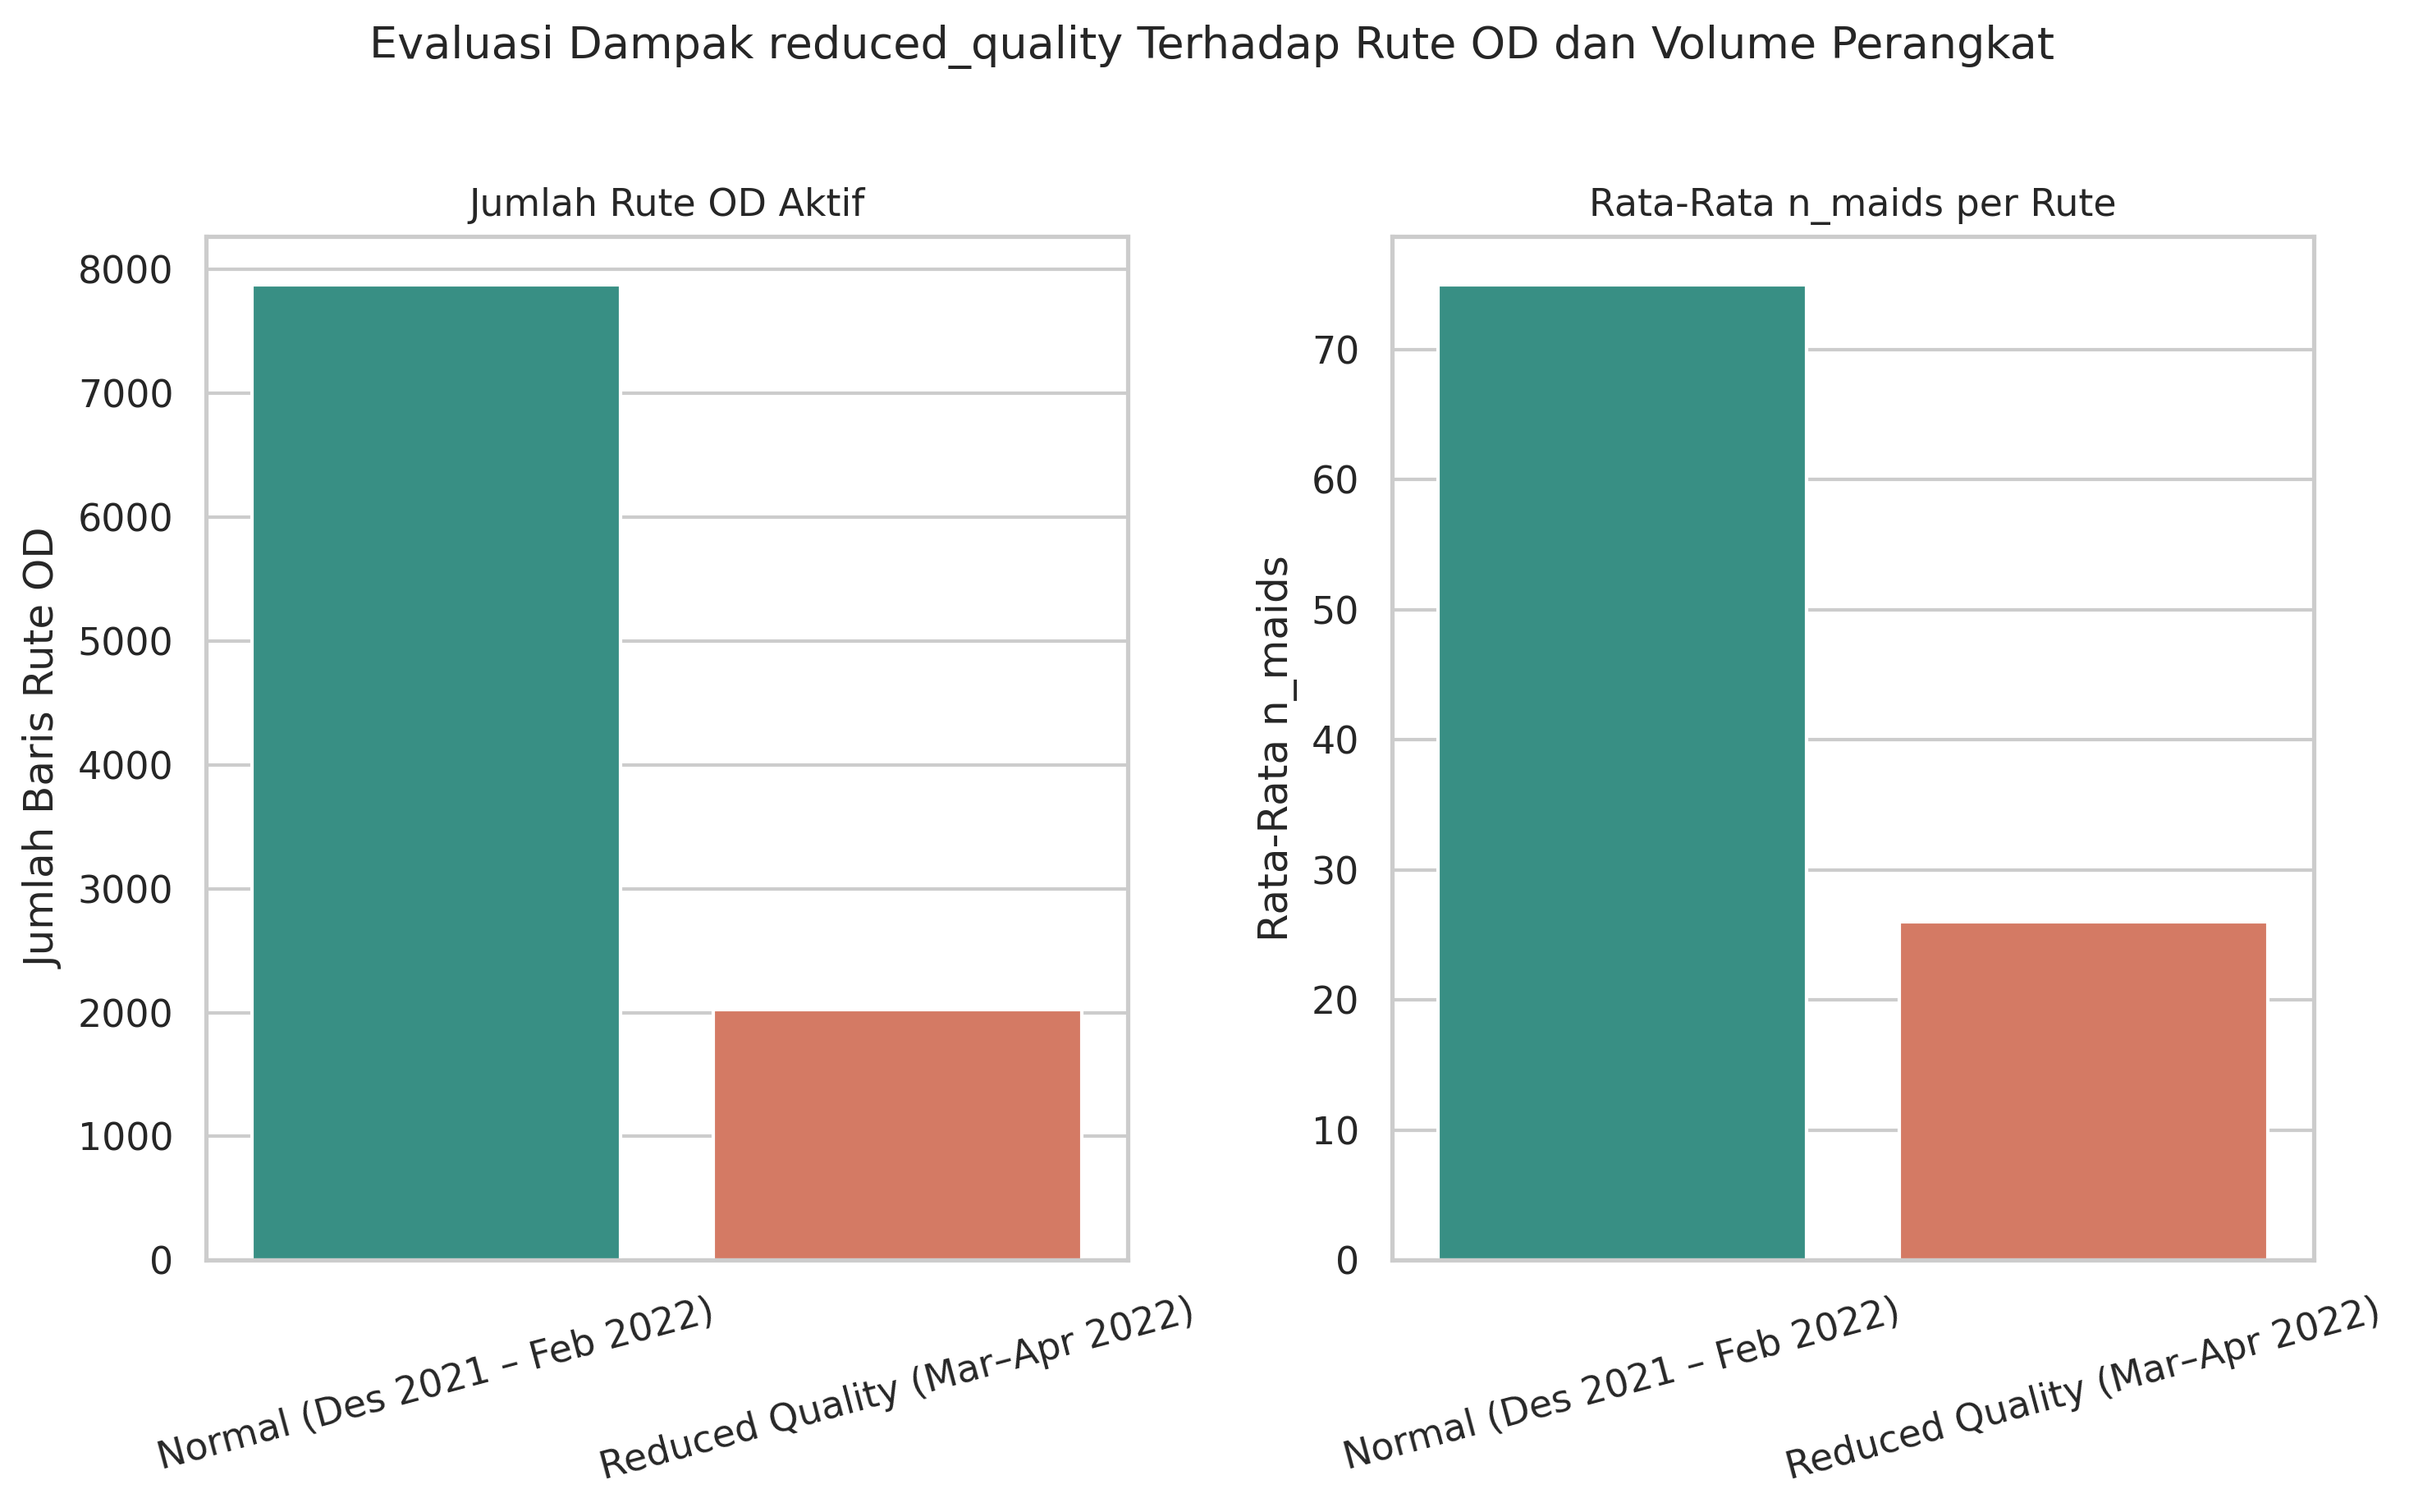

In [ ]:
df_od["status_kualitas"] = np.where(
    df_od["reduced_quality"].astype(str).str.lower() == "true",
    "Reduced Quality (Mar–Apr 2022)",
    "Normal (Des 2021 – Feb 2022)",
)

quality_summary = (
    df_od.groupby("status_kualitas")
    .agg(
        jumlah_rute_od=("n_maids", "count"),
        rata_rata_maids=("n_maids", "mean"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(10, 6), dpi=300)
sns.barplot(data=quality_summary, x="status_kualitas", y="jumlah_rute_od", palette=["#2a9d8f", "#e76f51"], ax=axes[0])
axes[0].set_title("Jumlah Rute OD Aktif", fontsize=11)
axes[0].set_xlabel("")
axes[0].set_ylabel("Jumlah Baris Rute OD")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(data=quality_summary, x="status_kualitas", y="rata_rata_maids", palette=["#2a9d8f", "#e76f51"], ax=axes[1])
axes[1].set_title("Rata-Rata n_maids per Rute", fontsize=11)
axes[1].set_xlabel("")
axes[1].set_ylabel("Rata-Rata n_maids")
axes[1].tick_params(axis="x", rotation=15)

fig.suptitle("Evaluasi Dampak reduced_quality Terhadap Rute OD dan Volume Perangkat", fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig("figures/08b_evaluasi_reduced_quality.png", dpi=300, bbox_inches="tight")
plt.show()